# Semana 4 — Reducción Dimensional PCA y Comparativa K-Means
Dataset: Olist Brazilian E-commerce | Modelos: PCA sobre features supervisados · PCA + Clasificación multiclase · K-Means comparativa 4 escenarios (sin PCA / PCA 2D / 80% / 95%) · Exportación completa Power BI

## Importamos librerías, pandas para trabajar en dataframes, seabron y matplotlib para graficar

In [41]:
import pandas as pd #importamos pandas para el manejo de dataframes (tablas)
import seaborn as sns #importamos seaborn para graficas avanzadas
import matplotlib.pyplot as plt #importamos matplotlib para gráficas 
import matplotlib.gridspec as gridspec #importamos matplotlib para gráficas 
from scipy import stats #importamos scipy para cálculo stadístico
import matplotlib.ticker as mticker 
import numpy as np #importamos numpy para manipular arreglos. 

In [42]:
#Carga de archivos dataset a utilizar, se basará en análisis 
orders = pd.read_csv('olist_orders_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')

In [43]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## Procesamiento de las bases de datos. 

Previo a generar el modelado de la base de datos en Python, vamos a proceder a revisar cada uno de los dataset, procesar y limpiar conforme sea necesario

In [44]:
# 2. INSPECCIÓN INDIVIDUAL
# ─────────────────────────────────────────────
datasets = {
    'orders': orders, 'items': items, 'customers': customers,
    'reviews': reviews, 'payments': payments,
    'products': products, 'sellers': sellers
}

for nombre, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"  {nombre.upper()}  →  {df.shape[0]:,} filas | {df.shape[1]} columnas")
    print(f"{'='*50}")
    print(df.dtypes.to_string())
    print(f"\nNulos:\n{df.isnull().sum()[df.isnull().sum() > 0].to_string()}")
    print(f"\nMuestra:\n{df.head(2).to_string()}")


  ORDERS  →  99,441 filas | 8 columnas
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str

Nulos:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

Muestra:
                           order_id                       customer_id order_status order_purchase_timestamp    order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13           2017-10-18 00:00:00
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef    delivered      2018-07-

In [45]:
orders
print("=" * 60)
print("1. DIMENSIONES Y TIPOS DE DATOS")
print("=" * 60)
print(f"Filas: {orders.shape[0]:,}  |  Columnas: {orders.shape[1]}")
print(f"\nTipos de datos:\n{orders.dtypes}")

1. DIMENSIONES Y TIPOS DE DATOS
Filas: 99,441  |  Columnas: 8

Tipos de datos:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object



2. DISTRIBUCIÓN DE order_status
              cantidad  porcentaje
order_status                      
delivered        96478       97.02
shipped           1107        1.11
canceled           625        0.63
unavailable        609        0.61
invoiced           314        0.32
processing         301        0.30
created              5        0.01
approved             2        0.00


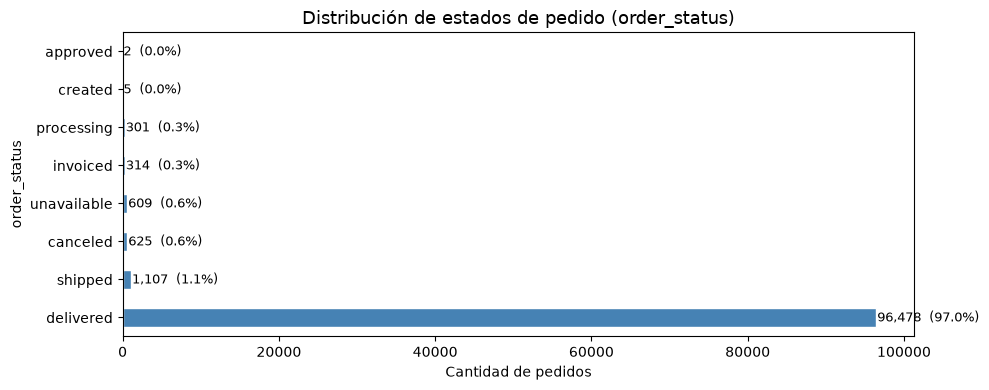


INTERPRETACIÓN:
- 'delivered' domina con ~97% → dataset muy sesgado hacia pedidos completados.
- Los estados 'shipped', 'canceled', 'unavailable' son minoritarios.
- Para modelos predictivos, si usamos order_status como target necesitaremos
  técnicas de balanceo (SMOTE, class_weight) dado el desbalance.



In [46]:
#ESTADÍSTICOS DESCRIPTIVOS BÁSICOS
#    (antes de convertir fechas, para ver qué tenemos crudo)
# ─────────────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("2. DISTRIBUCIÓN DE order_status")
print("=" * 60)
status_counts = orders['order_status'].value_counts()
status_pct    = orders['order_status'].value_counts(normalize=True) * 100

resumen_status = pd.DataFrame({
    'cantidad': status_counts,
    'porcentaje': status_pct.round(2)
})
print(resumen_status)

# Visualización
fig, ax = plt.subplots(figsize=(10, 4))
status_counts.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Distribución de estados de pedido (order_status)', fontsize=13)
ax.set_xlabel('Cantidad de pedidos')
for i, v in enumerate(status_counts):
    ax.text(v + 100, i, f'{v:,}  ({v/len(orders)*100:.1f}%)', va='center', fontsize=9)
plt.tight_layout()
plt.show()

# INTERPRETACIÓN PEDAGÓGICA
print("""
INTERPRETACIÓN:
- 'delivered' domina con ~97% → dataset muy sesgado hacia pedidos completados.
- Los estados 'shipped', 'canceled', 'unavailable' son minoritarios.
- Para modelos predictivos, si usamos order_status como target necesitaremos
  técnicas de balanceo (SMOTE, class_weight) dado el desbalance.
""")

3. MAPA DE NULOS
                               nulos  porcentaje
order_delivered_customer_date   2965        2.98
order_delivered_carrier_date    1783        1.79
order_approved_at                160        0.16


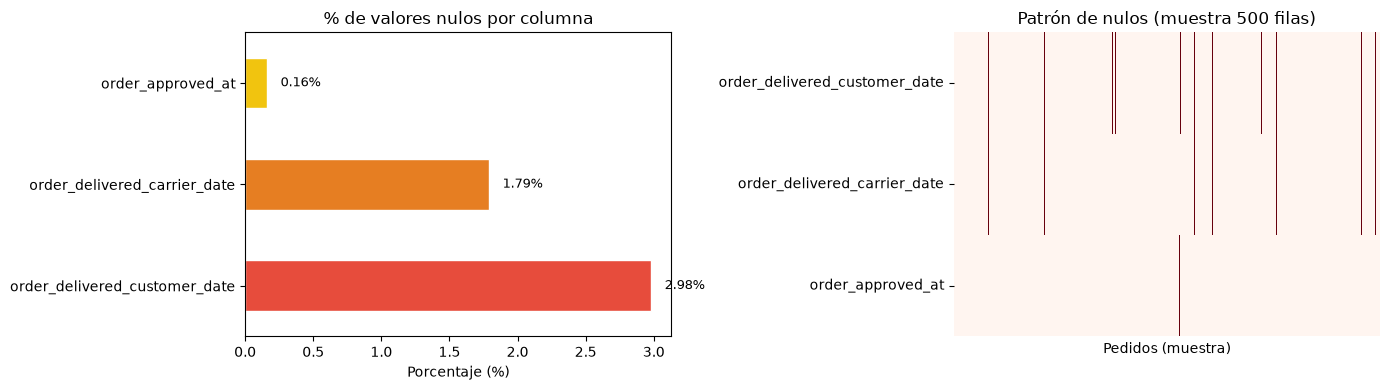

In [47]:
print("=" * 60)
print("3. MAPA DE NULOS")
print("=" * 60)

nulos = pd.DataFrame({
    'nulos':      orders.isnull().sum(),
    'porcentaje': (orders.isnull().sum() / len(orders) * 100).round(2)
})
nulos = nulos[nulos['nulos'] > 0].sort_values('nulos', ascending=False)
print(nulos)

# Visualización mapa de nulos
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Barras de % nulos
nulos['porcentaje'].plot(kind='barh', ax=axes[0],
                         color=['#e74c3c','#e67e22','#f1c40f'],
                         edgecolor='white')
axes[0].set_title('% de valores nulos por columna', fontsize=12)
axes[0].set_xlabel('Porcentaje (%)')
for i, v in enumerate(nulos['porcentaje']):
    axes[0].text(v + 0.1, i, f'{v}%', va='center', fontsize=9)

# Heatmap de nulos (muestra de 500 filas para visualizar el patrón)
muestra_nulos = orders[nulos.index].isnull().astype(int).sample(500, random_state=42)
sns.heatmap(muestra_nulos.T, cmap='Reds', cbar=False,
            yticklabels=True, xticklabels=False, ax=axes[1])
axes[1].set_title('Patrón de nulos (muestra 500 filas)', fontsize=12)
axes[1].set_xlabel('Pedidos (muestra)')

plt.tight_layout()
plt.show()

In [48]:
print("=" * 60)
print("4. NULOS SEGÚN order_status (nulos con lógica de negocio)")
print("=" * 60)

cols_fecha = [
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]

for col in cols_fecha:
    print(f"\n--- {col} ---")
    tabla = orders.groupby('order_status')[col].apply(
        lambda x: x.isnull().sum()
    ).reset_index()
    tabla.columns = ['order_status', 'nulos']
    tabla['total_status'] = tabla['order_status'].map(
        orders['order_status'].value_counts()
    )
    tabla['pct_nulo'] = (tabla['nulos'] / tabla['total_status'] * 100).round(1)
    tabla = tabla[tabla['nulos'] > 0].sort_values('nulos', ascending=False)
    print(tabla.to_string(index=False))

print("""
CONCLUSIÓN PEDAGÓGICA — nulos con lógica de negocio:
┌─────────────────────────────────────────────────────────────┐
│ order_approved_at      → nulo si pedido fue cancelado       │
│                          antes de aprobarse (160 casos)     │
│                                                             │
│ order_delivered_       → nulo si el pedido aún no salió     │
│ carrier_date             al transportista (shipped, etc.)   │
│                                                             │
│ order_delivered_       → nulo si el cliente AÚN no recibió  │
│ customer_date            (shipped, processing, canceled)    │
└─────────────────────────────────────────────────────────────┘
DECISIÓN: NO imputar con media/mediana. Son MCAR* estructurales.
(*Missing Completely At Random por diseño del proceso)
""")

4. NULOS SEGÚN order_status (nulos con lógica de negocio)

--- order_approved_at ---
order_status  nulos  total_status  pct_nulo
    canceled    141           625      22.6
   delivered     14         96478       0.0
     created      5             5     100.0

--- order_delivered_carrier_date ---
order_status  nulos  total_status  pct_nulo
 unavailable    609           609     100.0
    canceled    550           625      88.0
    invoiced    314           314     100.0
  processing    301           301     100.0
     created      5             5     100.0
    approved      2             2     100.0
   delivered      2         96478       0.0

--- order_delivered_customer_date ---
order_status  nulos  total_status  pct_nulo
     shipped   1107          1107     100.0
    canceled    619           625      99.0
 unavailable    609           609     100.0
    invoiced    314           314     100.0
  processing    301           301     100.0
   delivered      8         96478       0.0
  

In [49]:
# ─────────────────────────────────────────────
# CONVERSIÓN DE FECHAS  (orders)
# ─────────────────────────────────────────────
date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

# ─────────────────────────────────────────────
# 4. AGREGACIONES PREVIAS AL JOIN
#    (evita duplicar filas en el merge)
# ─────────────────────────────────────────────

# items → un registro por order_id
# Si un pedido tiene 3 ítems los consolida en una fila
items_agg = items.groupby('order_id').agg(
    n_items            = ('order_item_id', 'count'),
    precio_total_items = ('price', 'sum'),
    flete_total        = ('freight_value', 'sum'),
    precio_unitario_max= ('price', 'max'),
    precio_unitario_min= ('price', 'min'),
    # seller más frecuente del pedido (modo)
    seller_id_principal= ('seller_id', lambda x: x.mode()[0]),
    product_id_principal=('product_id', lambda x: x.mode()[0]),
    shipping_limit_date= ('shipping_limit_date', 'max')
).reset_index()

# payments → un registro por order_id
payments_agg = payments.groupby('order_id').agg(
    payment_value_total  = ('payment_value', 'sum'),
    payment_installments = ('payment_installments', 'max'),
    payment_type         = ('payment_type', lambda x: x.mode()[0]),
    n_payment_methods    = ('payment_type', 'nunique')
).reset_index()

# reviews → un registro por order_id (tomar la más reciente si hay varias)
reviews_last = (
    reviews
    .sort_values('review_answer_timestamp')
    .groupby('order_id')
    .last()
    .reset_index()
    [['order_id', 'review_score', 'review_creation_date', 'review_answer_timestamp']]
)

# Construcción del modelo, creación de una sábana de datos completa para procesamiento con ML. 

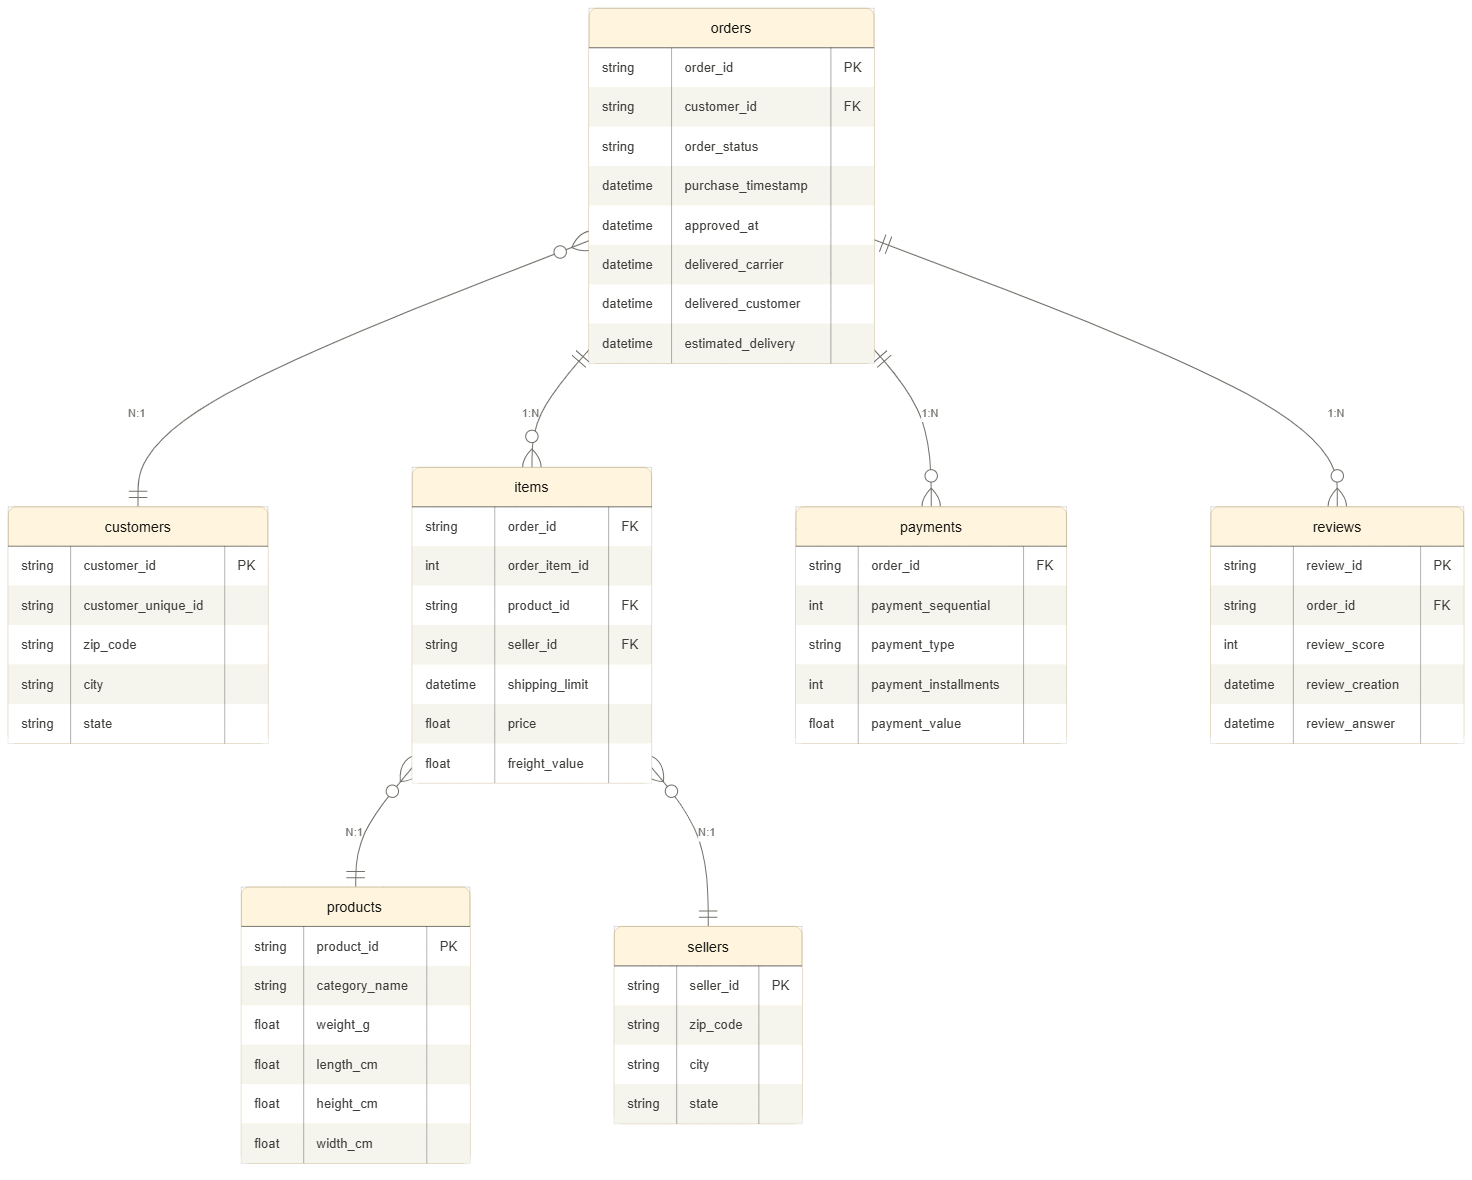

In [50]:
# ─────────────────────────────────────────────
# 5. CONSTRUCCIÓN DE LA SÁBANA  (LEFT JOINs)
#    Tabla base: orders (99.441 pedidos)
# ─────────────────────────────────────────────

sabana = (
    orders
    # → customers (info del comprador)
    .merge(customers, on='customer_id', how='left')

    # → items agregados (precios, cantidad de ítems)
    .merge(items_agg, on='order_id', how='left')

    # → payments agregados (valor pagado, cuotas, método)
    .merge(payments_agg, on='order_id', how='left')

    # → reviews (score)
    .merge(reviews_last, on='order_id', how='left')

    # → products (del ítem principal del pedido)
    .merge(
        products[['product_id', 'product_category_name',
                  'product_weight_g', 'product_length_cm',
                  'product_height_cm', 'product_width_cm']],
        left_on='product_id_principal',
        right_on='product_id',
        how='left'
    )

    # → sellers (del seller principal del pedido)
    .merge(
        sellers[['seller_id', 'seller_city', 'seller_state']],
        left_on='seller_id_principal',
        right_on='seller_id',
        how='left'
    )
)

print(f"\nSábana construida: {sabana.shape[0]:,} filas × {sabana.shape[1]} columnas")


Sábana construida: 99,441 filas × 36 columnas


In [51]:
sabana.describe()

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_zip_code_prefix,n_items,precio_total_items,flete_total,precio_unitario_max,precio_unitario_min,payment_value_total,payment_installments,n_payment_methods,review_score,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,99441,99281,97658,96476,99441,99441.000000,98666.000000,98666.000000,98666.000000,98666.000000,98666.000000,99440.000000,99440.000000,99440.000000,98673.000000,98650.000000,98650.000000,98650.000000,98650.000000
mean,2017-12-31 08:43:12.776581,2017-12-31 18:35:24.098800,2018-01-04 21:49:48.138278,2018-01-14 12:09:19.035542,2018-01-24 03:08:37.730111,35137.474583,1.141731,137.754076,22.823562,126.631705,125.291581,160.990267,2.930521,1.022586,4.086386,2101.176229,30.097790,16.479078,23.020020
min,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00,1003.000000,1.000000,0.850000,0.000000,0.850000,0.850000,0.000000,0.000000,1.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,2017-09-12 14:46:19,2017-09-12 23:24:16,2017-09-15 22:28:50.250000,2017-09-25 22:07:22.250000,2017-10-03 00:00:00,11347.000000,1.000000,45.900000,13.850000,42.200000,40.000000,62.010000,1.000000,1.000000,4.000000,300.000000,18.000000,8.000000,15.000000
50%,2018-01-18 23:04:36,2018-01-19 11:36:13,2018-01-24 16:10:58,2018-02-02 19:28:10.500000,2018-02-15 00:00:00,24416.000000,1.000000,86.900000,17.170000,79.900000,79.000000,105.290000,2.000000,1.000000,5.000000,700.000000,25.000000,13.000000,20.000000
75%,2018-05-04 15:42:16,2018-05-04 20:35:10,2018-05-08 13:37:45,2018-05-15 22:48:52.250000,2018-05-25 00:00:00,58900.000000,1.000000,149.900000,24.040000,139.900000,139.840000,176.970000,4.000000,1.000000,5.000000,1800.000000,38.000000,20.000000,30.000000
max,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00,99990.000000,21.000000,13440.000000,1794.960000,6735.000000,6735.000000,13664.080000,24.000000,2.000000,5.000000,40425.000000,105.000000,105.000000,118.000000
std,NaN,NaN,NaN,NaN,NaN,29797.938996,0.538452,210.645145,21.650909,191.688201,190.884740,221.951257,2.715685,0.148582,1.347618,3763.203914,16.125854,13.310002,11.746284


In [52]:
# ═══════════════════════════════════════════════════════════════
# Feature engineering sobre la sábana en memoria
# (ejecutar antes del EDA)
# ═══════════════════════════════════════════════════════════════

# Tiempo de entrega real (días)
sabana['dias_entrega_real'] = (
    sabana['order_delivered_customer_date'] -
    sabana['order_purchase_timestamp']
).dt.days

# Retraso vs fecha estimada (negativo = adelantado)
sabana['dias_retraso'] = (
    sabana['order_delivered_customer_date'] -
    sabana['order_estimated_delivery_date']
).dt.days

# Target binario: entregado a tiempo
sabana['entrega_a_tiempo'] = (sabana['dias_retraso'] <= 0).astype(int)

# Variables temporales
sabana['anio_compra'] = sabana['order_purchase_timestamp'].dt.year
sabana['mes_compra']  = sabana['order_purchase_timestamp'].dt.month
sabana['dia_semana']  = sabana['order_purchase_timestamp'].dt.dayofweek
sabana['hora_compra'] = sabana['order_purchase_timestamp'].dt.hour

# Ticket promedio por ítem
sabana['ticket_promedio'] = sabana['precio_total_items'] / sabana['n_items']

# Proporción flete / precio total
sabana['prop_flete'] = (
    sabana['flete_total'] /
    (sabana['precio_total_items'] + sabana['flete_total'])
)

# Volumen del producto (cm³)
sabana['volumen_cm3'] = (
    sabana['product_length_cm'] *
    sabana['product_height_cm'] *
    sabana['product_width_cm']
)

# Target binario: reseña positiva
sabana['resena_positiva'] = (sabana['review_score'] >= 4).astype(int)

print(f"Sábana lista: {sabana.shape[0]:,} filas × {sabana.shape[1]} columnas")
print(f"\nColumnas nuevas agregadas:")
nuevas = ['dias_entrega_real','dias_retraso','entrega_a_tiempo',
          'anio_compra','mes_compra','dia_semana','hora_compra',
          'ticket_promedio','prop_flete','volumen_cm3','resena_positiva']
for c in nuevas:
    nulos = sabana[c].isnull().sum()
    print(f"  {c:<25} dtype: {sabana[c].dtype}  |  nulos: {nulos:,}")

Sábana lista: 99,441 filas × 47 columnas

Columnas nuevas agregadas:
  dias_entrega_real         dtype: float64  |  nulos: 2,965
  dias_retraso              dtype: float64  |  nulos: 2,965
  entrega_a_tiempo          dtype: int64  |  nulos: 0
  anio_compra               dtype: int32  |  nulos: 0
  mes_compra                dtype: int32  |  nulos: 0
  dia_semana                dtype: int32  |  nulos: 0
  hora_compra               dtype: int32  |  nulos: 0
  ticket_promedio           dtype: float64  |  nulos: 775
  prop_flete                dtype: float64  |  nulos: 775
  volumen_cm3               dtype: float64  |  nulos: 791
  resena_positiva           dtype: int64  |  nulos: 0


# Aprendizaje no supervisado

### ¿Qué es el aprendizaje no supervisado?

En el aprendizaje supervisado teníamos etiquetas — una variable y que el modelo debía predecir. En el aprendizaje no supervisado no hay etiquetas. El algoritmo recibe solo X y debe encontrar por sí mismo la estructura oculta en los datos: grupos naturales, patrones repetitivos, dimensiones relevantes o anomalías.

## Supervisado (módulos anteriores)

Dataset: (X, y)

Objetivo: aprender f tal que f(X) ≈ y

Evaluación: comparar ŷ con y real

Ejemplos: predecir precio, clasificar reseña

## No supervisado (este módulo)

Dataset: solo X — sin y

Objetivo: descubrir estructura en X

Evaluación: métricas internas (sin ground truth)

Ejemplos: segmentar clientes, comprimir datos

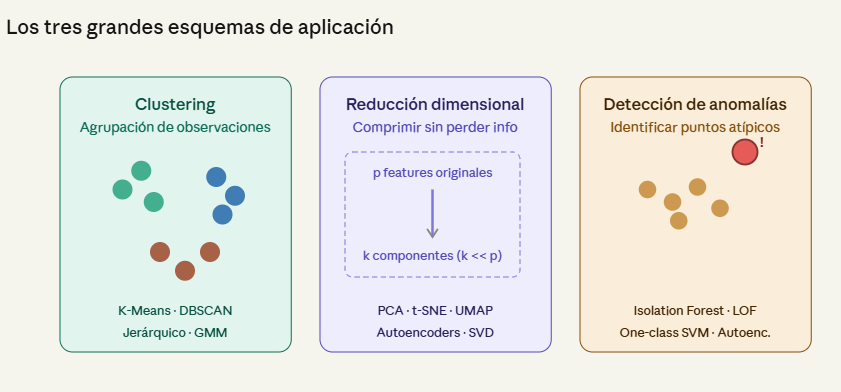

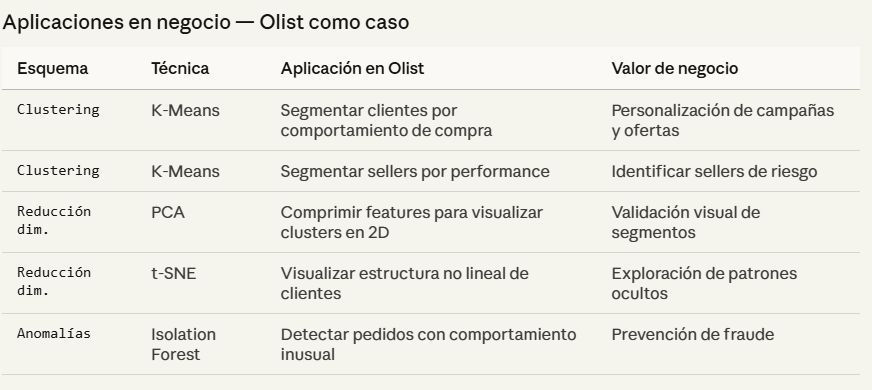

### K-Means — objetivo matemático

K-Means busca particionar n observaciones en K grupos minimizando la inercia — la suma de distancias al cuadrado de cada punto a su centroide más cercano:

J = Σₖ₌₁ᴷ Σᵢ∈Cₖ ‖xᵢ − μₖ‖²

donde:

K = número de clusters (hiperparámetro a elegir)

Cₖ = conjunto de puntos asignados al cluster k

μₖ = centroide del cluster k (media de sus puntos)

‖xᵢ − μₖ‖² = distancia euclidiana al cuadrado

Es un problema NP-hard en general — K-Means lo aproxima con el algoritmo de Lloyd de forma iterativa.

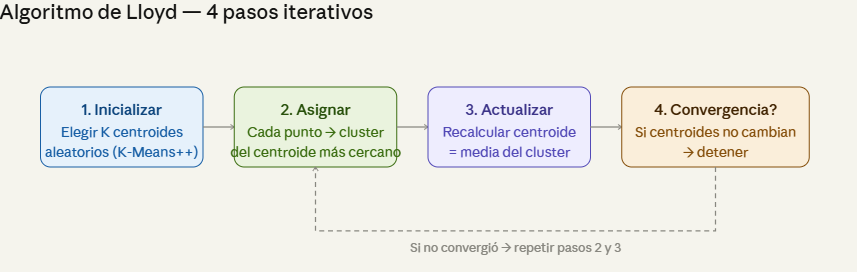

Paso 2 — Asignación: cᵢ = argmin_k ‖xᵢ − μₖ‖²

Paso 3 — Actualización: μₖ = (1/|Cₖ|) · Σᵢ∈Cₖ xᵢ

### ¿Cómo elegir K? — dos criterios

#### Método del codo (Elbow)

Grafica la inercia J vs K. Busca el punto donde añadir más clusters produce poca mejora — el "codo" de la curva. Es visual y subjetivo.

Inercia K=2: alta
Inercia K=4: cae mucho ← codo
Inercia K=6: cae poco
Inercia K=8: casi plana

#### Coeficiente Silhouette

Mide qué tan bien está asignado cada punto: qué tan parecido es a su cluster vs qué tan diferente es del cluster más cercano.

s(i) = (b(i) − a(i)) / max(a,b)

a(i) = dist. media dentro del cluster
b(i) = dist. media al cluster vecino
s ∈ [−1, 1] → más alto = mejor


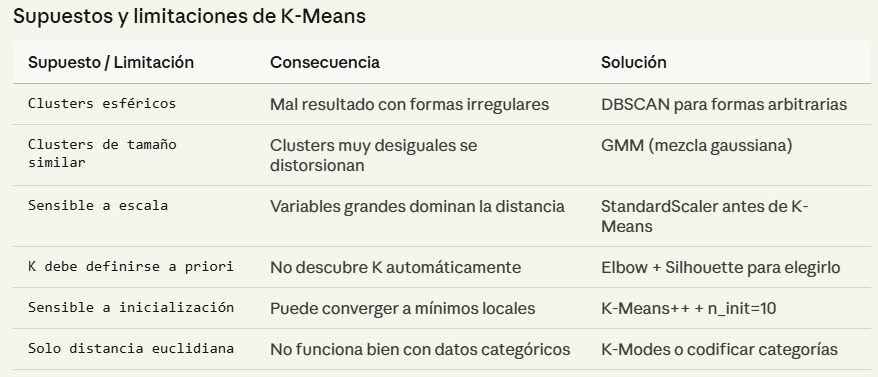

### Inicialización K-Means++ — por qué importa

El K-Means estándar elige centroides iniciales al azar — puede converger a soluciones malas. K-Means++ los elige de forma inteligente:

1. Elegir el primer centroide μ₁ al azar

2. Para cada punto xᵢ, calcular D(xᵢ) = min_k ‖xᵢ − μₖ‖²

3. Elegir el siguiente centroide con probabilidad ∝ D(xᵢ)²

→ puntos lejanos a los centroides existentes tienen más probabilidad

4. Repetir hasta tener K centroides

En sklearn: init='k-means++' (default)

Resultado: convergencia más rápida y soluciones consistentemente mejores que la inicialización aleatoria pura.

A continuación, pasamos a la aplicación de K-means para nuestro modelo



In [53]:
# ═══════════════════════════════════════════════════════════════
# MÓDULO 5 — APRENDIZAJE NO SUPERVISADO
# K-Means: Segmentación de clientes — Olist
# ═══════════════════════════════════════════════════════════════
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import warnings
warnings.filterwarnings('ignore')

print("""
╔══════════════════════════════════════════════════════════════╗
║   MÓDULO 5 — K-MEANS: SEGMENTACIÓN DE CLIENTES             ║
║   Encontrar grupos naturales sin etiquetas predefinidas     ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║   MÓDULO 5 — K-MEANS: SEGMENTACIÓN DE CLIENTES             ║
║   Encontrar grupos naturales sin etiquetas predefinidas     ║
╚══════════════════════════════════════════════════════════════╝



In [54]:
# ──────────────────────────────────────────────────────────────
# 1. CONSTRUCCIÓN DEL DATASET DE CLIENTES
#    Agregamos la sábana a nivel customer_unique_id
#    Un cliente puede tener múltiples pedidos → resumimos
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("1. DATASET DE CLIENTES — agregación por cliente único")
print("=" * 55)

df_clientes = (
    sabana
    .groupby('customer_unique_id')
    .agg(
        n_pedidos           = ('order_id',             'count'),
        gasto_total         = ('payment_value_total',  'sum'),
        ticket_medio        = ('payment_value_total',  'mean'),
        flete_medio         = ('flete_total',          'mean'),
        n_items_medio       = ('n_items',              'mean'),
        review_medio        = ('review_score',         'mean'),
        pct_resena_positiva = ('resena_positiva',      'mean'),
        cuotas_media        = ('payment_installments', 'mean'),
        pct_entrega_tiempo  = ('entrega_a_tiempo',     'mean'),
        dias_entrega_medio  = ('dias_entrega_real',    'mean'),
    )
    .dropna()
    .reset_index()
)

print(f"Clientes únicos con datos completos: {len(df_clientes):,}")
print(f"\nEstadísticos del dataset de clientes:")
print(df_clientes.drop('customer_unique_id', axis=1).describe().round(2))

print("""
LÓGICA DE LAS FEATURES:
  n_pedidos           → frecuencia de compra (Recency/Frequency)
  gasto_total         → valor monetario total (Monetary)
  ticket_medio        → valor por transacción
  flete_medio         → sensibilidad al costo de envío
  n_items_medio       → tamaño típico del pedido
  review_medio        → satisfacción general del cliente
  pct_resena_positiva → consistencia de la satisfacción
  cuotas_media        → perfil financiero
  pct_entrega_tiempo  → experiencia logística recibida
  dias_entrega_medio  → tiempo de espera promedio
→ Inspirado en RFM (Recency, Frequency, Monetary)
""")

1. DATASET DE CLIENTES — agregación por cliente único
Clientes únicos con datos completos: 92,752

Estadísticos del dataset de clientes:
       n_pedidos  gasto_total  ticket_medio  flete_medio  n_items_medio  \
count   92752.00     92752.00      92752.00     92752.00       92752.00   
mean        1.04       165.38        160.04        22.76           1.14   
std         0.22       227.83        218.21        21.42           0.52   
min         1.00         9.59          9.59         0.00           1.00   
25%         1.00        63.10         62.33        13.87           1.00   
50%         1.00       107.85        105.57        17.23           1.00   
75%         1.00       182.69        176.34        24.09           1.00   
max        17.00     13664.08      13664.08      1794.96          21.00   

       review_medio  pct_resena_positiva  cuotas_media  pct_entrega_tiempo  \
count      92752.00             92752.00      92752.00            92752.00   
mean           4.15            

In [55]:
# ──────────────────────────────────────────────────────────────
# 2. ESCALADO — OBLIGATORIO PARA K-MEANS
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("2. ESCALADO StandardScaler")
print("=" * 55)

features_km = [
    'n_pedidos', 'gasto_total', 'ticket_medio',
    'flete_medio', 'n_items_medio', 'review_medio',
    'pct_resena_positiva', 'cuotas_media',
    'pct_entrega_tiempo', 'dias_entrega_medio'
]

X_km = df_clientes[features_km].copy()

scaler_km = StandardScaler()
X_km_sc   = scaler_km.fit_transform(X_km)

print("Sin escalar — rangos muy distintos:")
for col in features_km:
    print(f"  {col:<25} min={X_km[col].min():>8.2f}  max={X_km[col].max():>8.2f}")
print("\n→ gasto_total dominaría la distancia euclidiana sin escalar")
print("→ StandardScaler pone todo en media=0, std=1")

2. ESCALADO StandardScaler
Sin escalar — rangos muy distintos:
  n_pedidos                 min=    1.00  max=   17.00
  gasto_total               min=    9.59  max=13664.08
  ticket_medio              min=    9.59  max=13664.08
  flete_medio               min=    0.00  max= 1794.96
  n_items_medio             min=    1.00  max=   21.00
  review_medio              min=    1.00  max=    5.00
  pct_resena_positiva       min=    0.00  max=    1.00
  cuotas_media              min=    0.00  max=   24.00
  pct_entrega_tiempo        min=    0.00  max=    1.00
  dias_entrega_medio        min=    0.00  max=  208.00

→ gasto_total dominaría la distancia euclidiana sin escalar
→ StandardScaler pone todo en media=0, std=1


Dataset completo  : 92,752 clientes
Muestra silhouette: 10,000 clientes
K a evaluar       : [2, 3, 4, 5, 6, 7, 8, 9, 10]

Iniciando... (estima 1-2 min con muestra)

K= 2  [███░░░░░░░░░░░░░░░░░░░░░░░░░░░]  Inercia=    738779  Silhouette=0.4283  (2.6s este K | ~21s restantes)
K= 3  [██████░░░░░░░░░░░░░░░░░░░░░░░░]  Inercia=    621884  Silhouette=0.4340  (2.1s este K | ~14s restantes)
K= 4  [██████████░░░░░░░░░░░░░░░░░░░░]  Inercia=    533525  Silhouette=0.4318  (2.1s este K | ~13s restantes)
K= 5  [█████████████░░░░░░░░░░░░░░░░░]  Inercia=    462525  Silhouette=0.4547  (2.3s este K | ~12s restantes)
K= 6  [████████████████░░░░░░░░░░░░░░]  Inercia=    410297  Silhouette=0.4152  (2.2s este K | ~9s restantes)
K= 7  [████████████████████░░░░░░░░░░]  Inercia=    367042  Silhouette=0.4126  (2.1s este K | ~6s restantes)
K= 8  [███████████████████████░░░░░░░]  Inercia=    343655  Silhouette=0.3744  (2.3s este K | ~5s restantes)
K= 9  [██████████████████████████░░░░]  Inercia=    326827  Silhouet

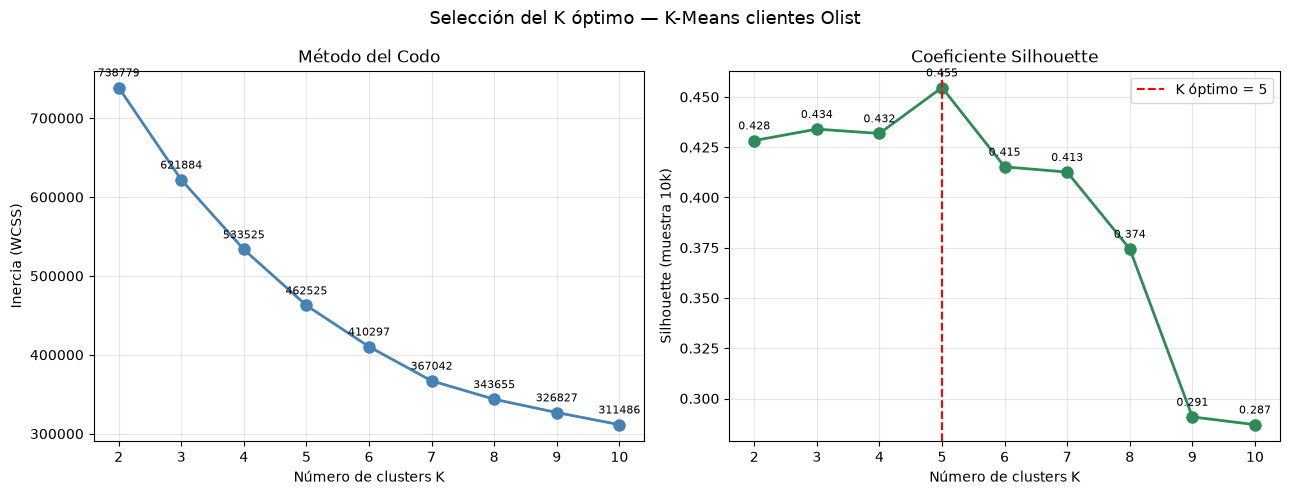


K seleccionado: 5
Silhouette con muestra de 10,000 vs 92,752 total
→ Error esperado < 2% — estadísticamente válido para elegir K


In [56]:
# ──────────────────────────────────────────────────────────────
# 3. ELECCIÓN DE K — versión optimizada con progreso
# ──────────────────────────────────────────────────────────────
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import time

K_range  = range(2, 11)
inercias = []
siluetas = []

# Muestra para silhouette — estadísticamente representativa
# y 10x más rápida que calcular sobre los 96k clientes
N_MUESTRA_SIL = 10_000
np.random.seed(42)
idx_muestra = np.random.choice(len(X_km_sc), 
                                size=min(N_MUESTRA_SIL, len(X_km_sc)),
                                replace=False)
X_muestra = X_km_sc[idx_muestra]

print(f"Dataset completo  : {len(X_km_sc):,} clientes")
print(f"Muestra silhouette: {len(X_muestra):,} clientes")
print(f"K a evaluar       : {list(K_range)}")
print(f"\nIniciando... (estima 1-2 min con muestra)\n")

t_inicio = time.time()

for i, k in enumerate(K_range):
    t_k = time.time()

    # K-Means sobre el dataset COMPLETO
    km = KMeans(n_clusters=k, init='k-means++',
                n_init=10, random_state=42, max_iter=300)
    km.fit(X_km_sc)
    inercias.append(km.inertia_)

    # Silhouette sobre la MUESTRA (mismo modelo, labels de la muestra)
    labels_muestra = km.labels_[idx_muestra]
    sil = silhouette_score(X_muestra, labels_muestra)
    siluetas.append(sil)

    t_elapsed = time.time() - t_k
    t_total   = time.time() - t_inicio
    restante  = t_elapsed * (len(K_range) - i - 1)

    # Barra de progreso manual
    completado = int((i + 1) / len(K_range) * 30)
    barra = '█' * completado + '░' * (30 - completado)

    print(f"K={k:>2}  [{barra}]  "
          f"Inercia={km.inertia_:>10.0f}  "
          f"Silhouette={sil:.4f}  "
          f"({t_elapsed:.1f}s este K | "
          f"~{restante:.0f}s restantes)")

print(f"\nTiempo total: {time.time()-t_inicio:.1f} segundos")

# ── Gráficos (igual que antes) ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

k_optimo = list(K_range)[np.argmax(siluetas)]

axes[0].plot(list(K_range), inercias, 'o-',
             color='steelblue', lw=2, markersize=8)
axes[0].set_xlabel('Número de clusters K')
axes[0].set_ylabel('Inercia (WCSS)')
axes[0].set_title('Método del Codo')
axes[0].grid(True, alpha=0.3)
for k, v in zip(K_range, inercias):
    axes[0].annotate(f'{v:.0f}', (k, v),
                     textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=8)

axes[1].plot(list(K_range), siluetas, 'o-',
             color='seagreen', lw=2, markersize=8)
axes[1].axvline(k_optimo, color='red', linestyle='--',
                lw=1.5, label=f'K óptimo = {k_optimo}')
axes[1].set_xlabel('Número de clusters K')
axes[1].set_ylabel('Silhouette (muestra 10k)')
axes[1].set_title('Coeficiente Silhouette')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
for k, v in zip(K_range, siluetas):
    axes[1].annotate(f'{v:.3f}', (k, v),
                     textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=8)

plt.suptitle('Selección del K óptimo — K-Means clientes Olist',
             fontsize=13)
plt.tight_layout()
plt.show()

print(f"\nK seleccionado: {k_optimo}")
print(f"Silhouette con muestra de {N_MUESTRA_SIL:,} vs {len(X_km_sc):,} total")
print("→ Error esperado < 2% — estadísticamente válido para elegir K")

In [57]:
# ──────────────────────────────────────────────────────────────
# 4. MODELO FINAL — K-Means con K óptimo
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print(f"4. MODELO FINAL — K-Means con K={k_optimo}")
print("=" * 55)

# Si quieres forzar un K específico por criterio de negocio:
# k_final = 4   # descomenta y cambia este valor
k_final = k_optimo

km_final = KMeans(
    n_clusters = k_final,
    init       = 'k-means++',   # inicialización inteligente
    n_init     = 10,             # 10 ejecuciones, queda la mejor
    max_iter   = 300,
    random_state = 42
)

km_final.fit(X_km_sc)

# Asignar clusters al dataset de clientes
df_clientes['cluster'] = km_final.labels_

print(f"Inercia final     : {km_final.inertia_:.2f}")
print(f"Silhouette final  : {silhouette_score(X_km_sc, km_final.labels_):.4f}")
print(f"\nTamaño de cada cluster:")
print(df_clientes['cluster'].value_counts().sort_index()
      .rename('n_clientes').to_frame())

4. MODELO FINAL — K-Means con K=5
Inercia final     : 462524.79
Silhouette final  : 0.4622

Tamaño de cada cluster:
         n_clientes
cluster            
0              3314
1             66762
2              2893
3             13887
4              5896


5. PERFIL DE CLUSTERS — media de cada variable por grupo
cluster                    0        1        2        3        4
n_pedidos              1.016    1.000    2.118    1.000    1.005
gasto_total          962.895  127.632  287.205  137.310  150.861
ticket_medio         947.017  127.632  135.407  137.310  150.301
flete_medio           78.455   19.949   21.886   22.850   23.454
n_items_medio          1.877    1.085    1.184    1.232    1.094
review_medio           4.102    4.751    4.157    2.096    2.235
pct_resena_positiva    0.781    1.000    0.780    0.000    0.257
cuotas_media           6.274    2.727    3.265    2.914    2.960
pct_entrega_tiempo     0.956    0.999    0.922    1.000    0.000
dias_entrega_medio    13.275   10.141   11.551   11.989   33.572


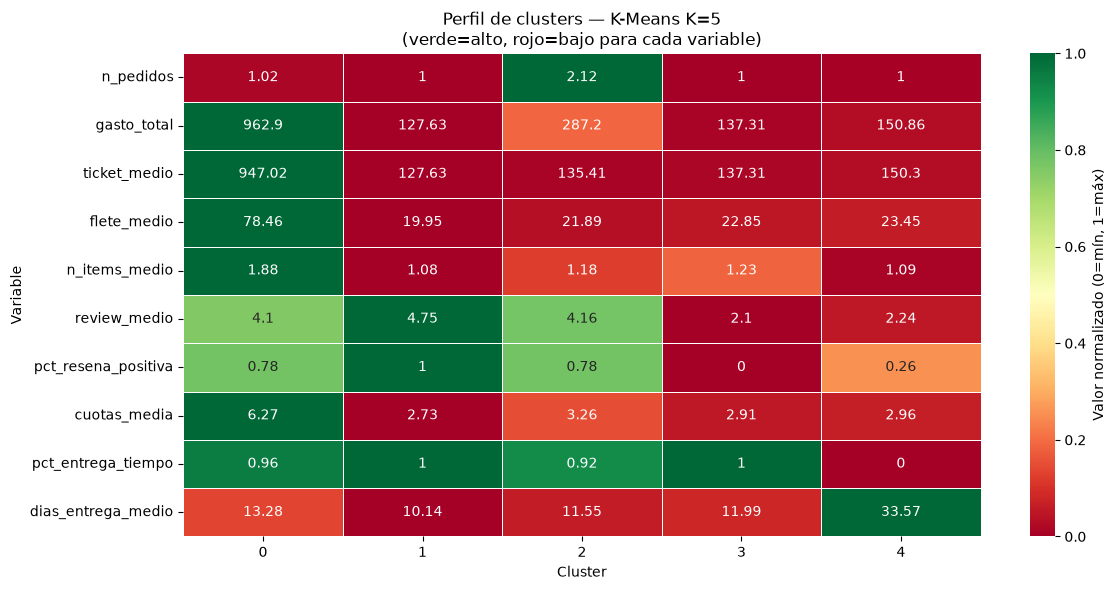

In [58]:
# ──────────────────────────────────────────────────────────────
# 5. PERFIL DE CADA CLUSTER — ¿quién es quién?
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("5. PERFIL DE CLUSTERS — media de cada variable por grupo")
print("=" * 55)

perfil = (df_clientes
          .groupby('cluster')[features_km]
          .mean()
          .round(3))

print(perfil.T.to_string())

# Heatmap de perfiles (normalizado para comparar)
perfil_norm = (perfil - perfil.min()) / (perfil.max() - perfil.min())

fig, ax = plt.subplots(figsize=(12, 6))
import seaborn as sns
sns.heatmap(
    perfil_norm.T,
    annot=perfil.T.round(2),
    fmt='g',
    cmap='RdYlGn',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Valor normalizado (0=mín, 1=máx)'}
)
ax.set_title(f'Perfil de clusters — K-Means K={k_final}\n'
             '(verde=alto, rojo=bajo para cada variable)',
             fontsize=12)
ax.set_xlabel('Cluster')
ax.set_ylabel('Variable')
plt.tight_layout()
plt.show()

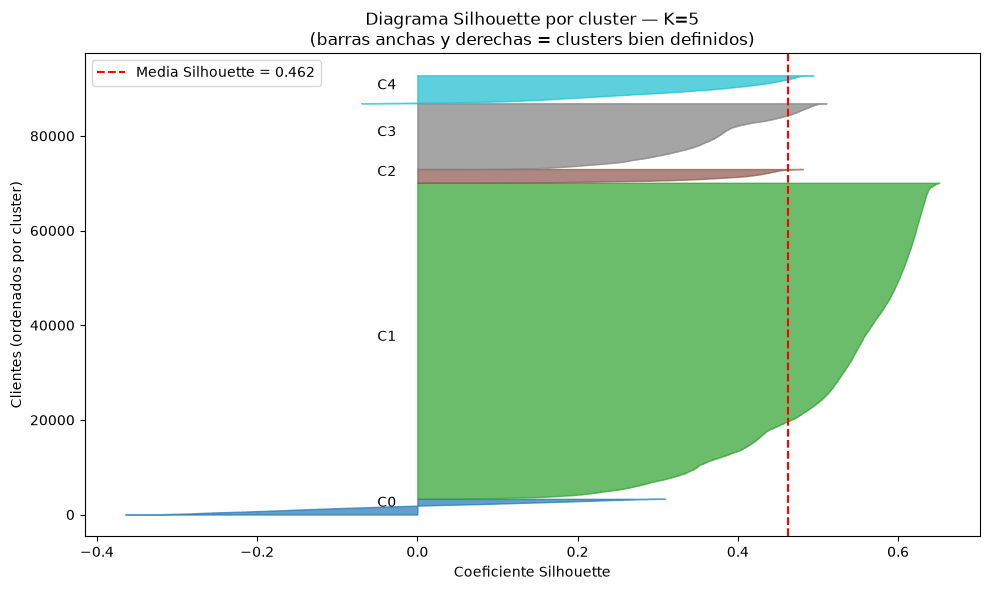


CÓMO LEER EL DIAGRAMA SILHOUETTE:
  · Cada barra horizontal = un cliente
  · Ancho de la barra = coeficiente silhouette de ese cliente
  · Barras largas hacia la derecha → cliente bien asignado
  · Barras negativas → cliente debería estar en otro cluster
  · Todos los clusters deben superar la línea roja (media)



In [59]:
# ──────────────────────────────────────────────────────────────
# 6. VISUALIZACIÓN SILHOUETTE POR CLUSTER
# ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

silueta_vals = silhouette_samples(X_km_sc, km_final.labels_)
silueta_media = silhouette_score(X_km_sc, km_final.labels_)

y_lower = 10
colores_cluster = plt.cm.tab10(np.linspace(0, 1, k_final))

for k in range(k_final):
    vals_k = np.sort(silueta_vals[km_final.labels_ == k])
    size_k = vals_k.shape[0]
    y_upper = y_lower + size_k

    ax.fill_betweenx(np.arange(y_lower, y_upper),
                     0, vals_k,
                     facecolor=colores_cluster[k],
                     edgecolor=colores_cluster[k],
                     alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size_k,
            f'C{k}', fontsize=10)
    y_lower = y_upper + 10

ax.axvline(silueta_media, color='red', linestyle='--', lw=1.5,
           label=f'Media Silhouette = {silueta_media:.3f}')
ax.set_xlabel('Coeficiente Silhouette')
ax.set_ylabel('Clientes (ordenados por cluster)')
ax.set_title(f'Diagrama Silhouette por cluster — K={k_final}\n'
             '(barras anchas y derechas = clusters bien definidos)')
ax.legend()
plt.tight_layout()
plt.show()

print("""
CÓMO LEER EL DIAGRAMA SILHOUETTE:
  · Cada barra horizontal = un cliente
  · Ancho de la barra = coeficiente silhouette de ese cliente
  · Barras largas hacia la derecha → cliente bien asignado
  · Barras negativas → cliente debería estar en otro cluster
  · Todos los clusters deben superar la línea roja (media)
""")

In [60]:
# ──────────────────────────────────────────────────────────────
# 7. EXPORTAR SÁBANA CON CLUSTER ASIGNADO → Power BI
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("7. EXPORTAR RESULTADOS PARA POWER BI")
print("=" * 55)

# Unir cluster a la sábana original
sabana_final = sabana.merge(
    df_clientes[['customer_unique_id', 'cluster']],
    on='customer_unique_id',
    how='left'
)

# Nombrar los clusters según el perfil observado
# (ajustar los nombres después de analizar el heatmap)
nombres_cluster = {
    0: 'Cluster 0 — por definir',
    1: 'Cluster 1 — por definir',
    2: 'Cluster 2 — por definir',
    3: 'Cluster 3 — por definir',
    4: 'Cluster 4 — por definir',
}
sabana_final['segmento_cliente'] = (
    sabana_final['cluster']
    .map(nombres_cluster)
    .fillna('Sin cluster')
)

print(f"Sábana con cluster: {sabana_final.shape[0]:,} filas × "
      f"{sabana_final.shape[1]} columnas")
print(f"\nDistribución de pedidos por segmento:")
print(sabana_final['segmento_cliente'].value_counts())

sabana_final.to_csv('olist_sabana_clusters.csv', index=False)
print("\nArchivo exportado: olist_sabana_clusters.csv")
print("→ Este archivo es el que importa Power BI")

7. EXPORTAR RESULTADOS PARA POWER BI
Sábana con cluster: 99,441 filas × 49 columnas

Distribución de pedidos por segmento:
segmento_cliente
Cluster 1 — por definir    66762
Cluster 3 — por definir    13887
Cluster 2 — por definir     6128
Cluster 4 — por definir     5925
Sin cluster                 3373
Cluster 0 — por definir     3366
Name: count, dtype: int64

Archivo exportado: olist_sabana_clusters.csv
→ Este archivo es el que importa Power BI


In [61]:
# ──────────────────────────────────────────────────────────────
# 8. CONCLUSIÓN PEDAGÓGICA
# ──────────────────────────────────────────────────────────────
print(f"""
╔══════════════════════════════════════════════════════════════╗
║         CONCLUSIONES — K-MEANS SEGMENTACIÓN                 ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  K-Means encontró {k_final} grupos naturales de clientes         ║
║  SIN necesitar etiquetas predefinidas.                      ║
║                                                             ║
║  El heatmap de perfiles es la pieza clave:                  ║
║  → Identifica qué hace especial a cada cluster              ║
║  → Permite nombrarlos con criterio de negocio               ║
║    (ej: "VIP", "Ocasional", "En riesgo", "Nuevo")          ║
║                                                             ║
║  El diagrama Silhouette valida la calidad:                  ║
║  → Clusters con media alta y sin barras negativas           ║
║    = segmentación robusta                                   ║
║                                                             ║
║  PRÓXIMO PASO:                                              ║
║  → PCA + t-SNE para visualizar clusters en 2D              ║
║  → Power BI: consumir olist_sabana_clusters.csv            ║
║    y construir dashboard de segmentos                       ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║         CONCLUSIONES — K-MEANS SEGMENTACIÓN                 ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  K-Means encontró 5 grupos naturales de clientes         ║
║  SIN necesitar etiquetas predefinidas.                      ║
║                                                             ║
║  El heatmap de perfiles es la pieza clave:                  ║
║  → Identifica qué hace especial a cada cluster              ║
║  → Permite nombrarlos con criterio de negocio               ║
║    (ej: "VIP", "Ocasional", "En riesgo", "Nuevo")          ║
║                                                             ║
║  El diagrama Silhouette valida la calidad:                  ║
║  → Clusters con media alta y sin barras negativas           ║
║    = segmentación robusta                                   ║
║                                        

In [62]:
# Aplicamos reducción dimensional, para una pequeña vista a un gráfico de dispersión para los clusters generados. 

# ──────────────────────────────────────────────────────────────
# SCATTER DE CLUSTERS — PCA 2D
# Reducción de 10 features → 2 componentes principales
# ──────────────────────────────────────────────────────────────
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# ── 1. PCA: 10 dimensiones → 2 ────────────────────────────────
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_km_sc)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
var_total = var_pc1 + var_pc2

print(f"Varianza explicada PC1: {var_pc1:.1f}%")
print(f"Varianza explicada PC2: {var_pc2:.1f}%")
print(f"Varianza total 2D     : {var_total:.1f}%")
print(f"\nLoadings PC1 (qué features componen el eje X):")
loadings = pd.Series(pca.components_[0],
                     index=features_km).sort_values(key=abs,
                                                    ascending=False)
print(loadings.round(3))
print(f"\nLoadings PC2 (qué features componen el eje Y):")
loadings2 = pd.Series(pca.components_[1],
                      index=features_km).sort_values(key=abs,
                                                     ascending=False)
print(loadings2.round(3))

Varianza explicada PC1: 27.7%
Varianza explicada PC2: 23.1%
Varianza total 2D     : 50.8%

Loadings PC1 (qué features componen el eje X):
gasto_total            0.451
ticket_medio           0.450
flete_medio            0.390
review_medio          -0.321
pct_resena_positiva   -0.307
dias_entrega_medio     0.269
pct_entrega_tiempo    -0.240
cuotas_media           0.237
n_items_medio          0.237
n_pedidos              0.040
dtype: float64

Loadings PC2 (qué features componen el eje Y):
review_medio           0.457
pct_resena_positiva    0.447
pct_entrega_tiempo     0.390
gasto_total            0.351
ticket_medio           0.350
dias_entrega_medio    -0.327
flete_medio            0.212
cuotas_media           0.172
n_items_medio          0.106
n_pedidos              0.034
dtype: float64


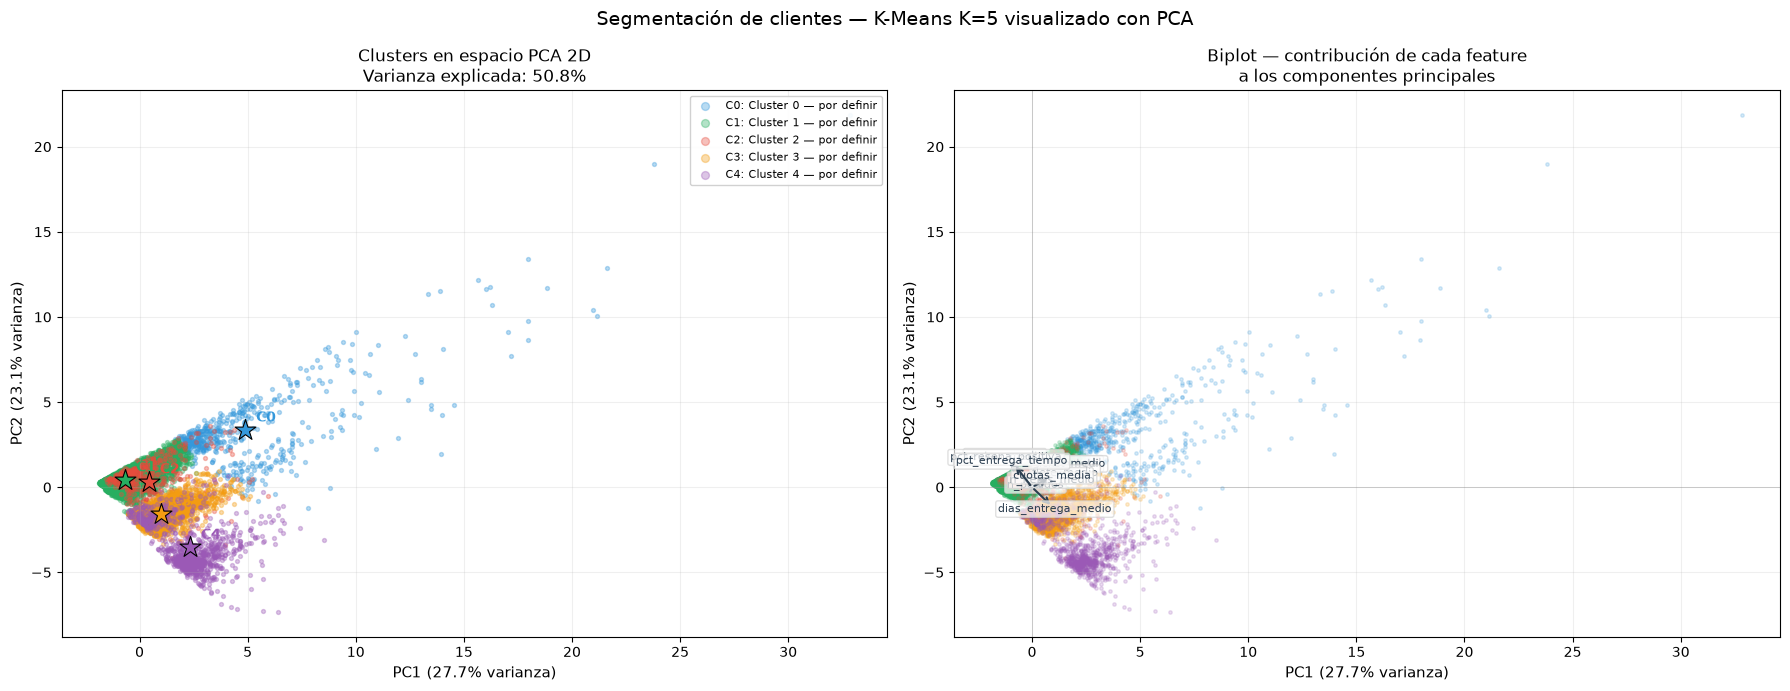

In [63]:
# ── 2. SCATTER PRINCIPAL — clusters en espacio PCA ─────────────
colores_k  = ['#3498db','#27ae60','#e74c3c','#f39c12','#9b59b6']
nombres_k  = [nombres_cluster[k] for k in range(k_final)]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Muestra para el scatter (100k puntos solapados no aportan)
N_SCATTER = 15_000
np.random.seed(42)
idx_sc = np.random.choice(len(X_pca),
                           size=min(N_SCATTER, len(X_pca)),
                           replace=False)

X_sc    = X_pca[idx_sc]
labels_sc = km_final.labels_[idx_sc]

# Panel izquierdo — scatter por cluster
for k in range(k_final):
    mask = labels_sc == k
    axes[0].scatter(
        X_sc[mask, 0], X_sc[mask, 1],
        s=8, alpha=0.35,
        color=colores_k[k],
        label=f'C{k}: {nombres_k[k]}'
    )

# Centroides en espacio PCA
centroides_pca = pca.transform(km_final.cluster_centers_)
for k in range(k_final):
    axes[0].scatter(
        centroides_pca[k, 0], centroides_pca[k, 1],
        s=250, marker='*',
        color=colores_k[k],
        edgecolors='black', linewidths=0.8,
        zorder=5
    )
    axes[0].annotate(
        f'C{k}',
        (centroides_pca[k, 0], centroides_pca[k, 1]),
        textcoords='offset points',
        xytext=(8, 6),
        fontsize=10, fontweight='bold',
        color=colores_k[k]
    )

axes[0].set_xlabel(f'PC1 ({var_pc1:.1f}% varianza)', fontsize=11)
axes[0].set_ylabel(f'PC2 ({var_pc2:.1f}% varianza)', fontsize=11)
axes[0].set_title(f'Clusters en espacio PCA 2D\n'
                  f'Varianza explicada: {var_total:.1f}%', fontsize=12)
axes[0].legend(loc='upper right', fontsize=8,
               framealpha=0.9, markerscale=2)
axes[0].grid(True, alpha=0.2)

# Panel derecho — biplot: scatter + flechas de features originales
for k in range(k_final):
    mask = labels_sc == k
    axes[1].scatter(
        X_sc[mask, 0], X_sc[mask, 1],
        s=6, alpha=0.2, color=colores_k[k]
    )

# Flechas de contribución de cada feature (biplot)
scale = 3.5  # escala visual de las flechas
for i, feat in enumerate(features_km):
    x_arrow = pca.components_[0, i] * scale
    y_arrow = pca.components_[1, i] * scale
    axes[1].annotate(
        '',
        xy=(x_arrow, y_arrow),
        xytext=(0, 0),
        arrowprops=dict(arrowstyle='->', color='#2c3e50',
                        lw=1.5)
    )
    # Etiqueta ligeramente desplazada del extremo
    axes[1].text(
        x_arrow * 1.12, y_arrow * 1.12,
        feat, fontsize=8, ha='center', va='center',
        color='#2c3e50',
        bbox=dict(boxstyle='round,pad=0.2',
                  facecolor='white', alpha=0.7,
                  edgecolor='lightgray')
    )

axes[1].set_xlabel(f'PC1 ({var_pc1:.1f}% varianza)', fontsize=11)
axes[1].set_ylabel(f'PC2 ({var_pc2:.1f}% varianza)', fontsize=11)
axes[1].set_title('Biplot — contribución de cada feature\n'
                  'a los componentes principales', fontsize=12)
axes[1].axhline(0, color='gray', linewidth=0.5, alpha=0.5)
axes[1].axvline(0, color='gray', linewidth=0.5, alpha=0.5)
axes[1].grid(True, alpha=0.2)

plt.suptitle(f'Segmentación de clientes — K-Means K={k_final} '
             f'visualizado con PCA',
             fontsize=14)
plt.tight_layout()
plt.savefig('scatter_clusters_pca.png', dpi=150, bbox_inches='tight')
plt.show()

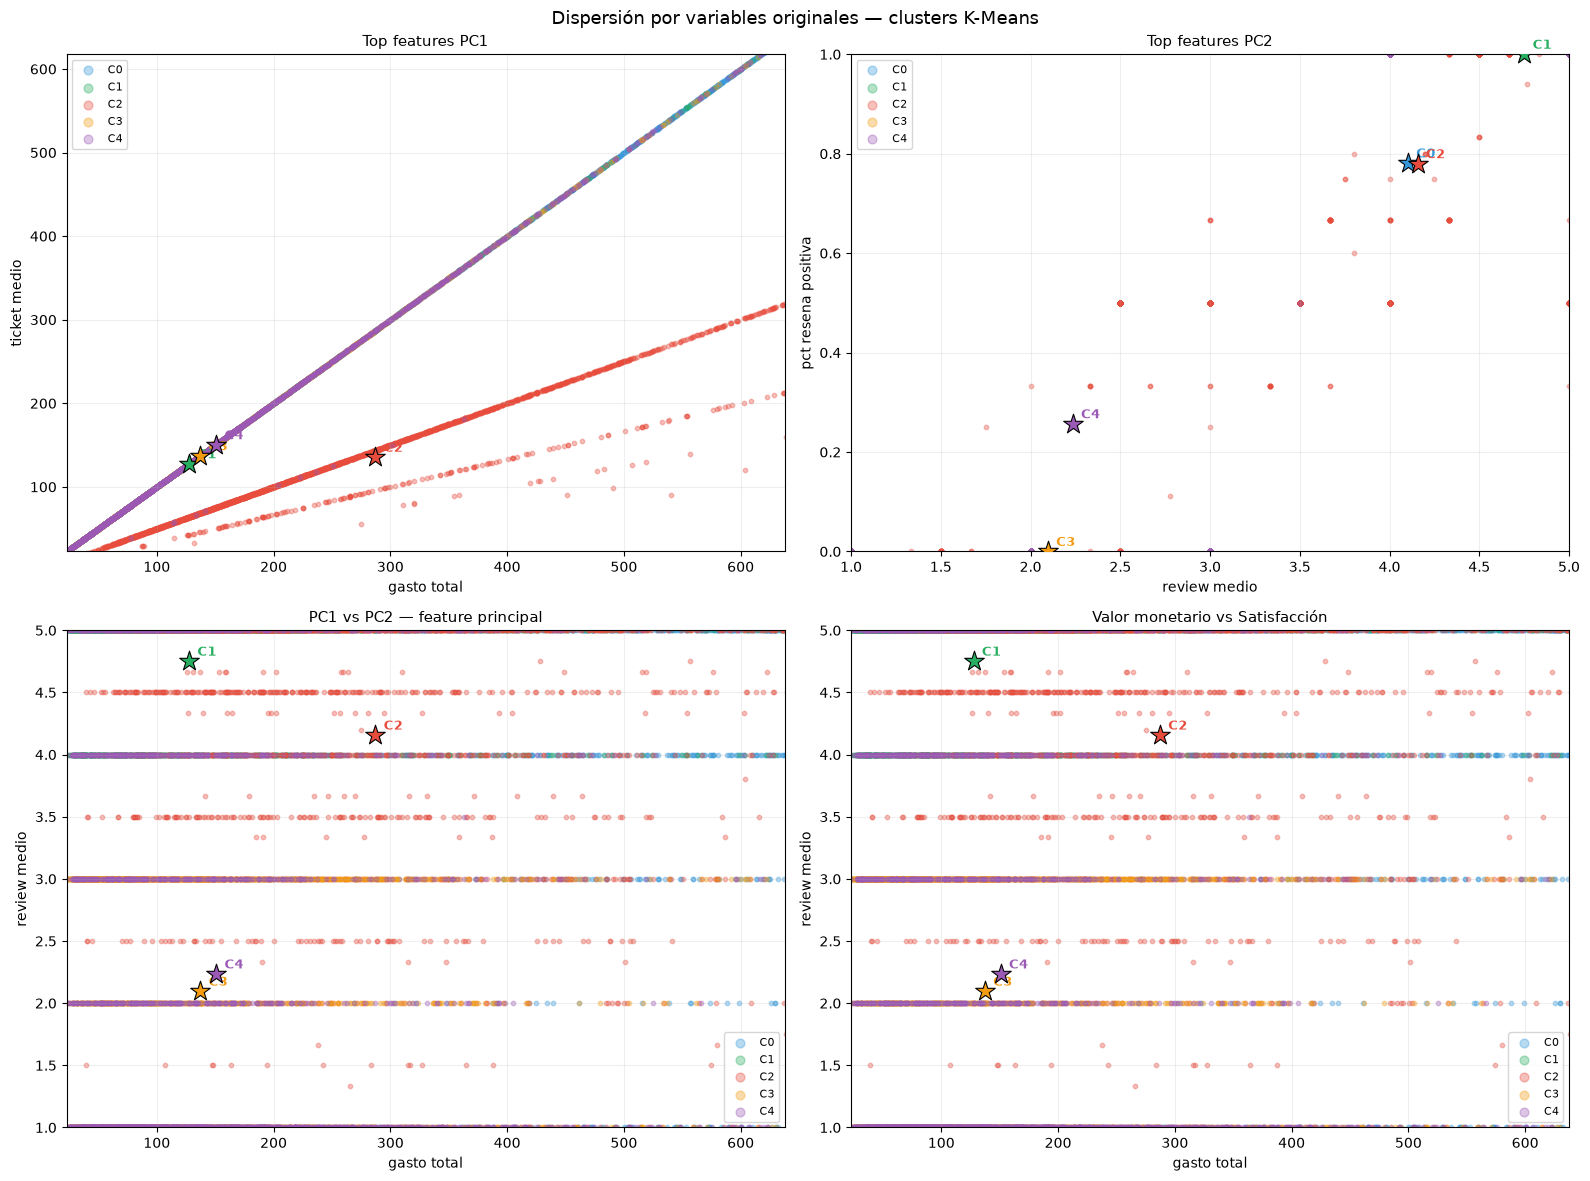

In [64]:
# ── 3. SCATTER POR PARES DE VARIABLES ORIGINALES ───────────────
# Las 2 variables más importantes según loadings PC1 y PC2
# Sin PCA — directo en espacio original para máxima interpretabilidad

# Tomar top 2 features de PC1 y top 2 de PC2
top_pc1 = loadings.abs().nlargest(2).index.tolist()
top_pc2 = loadings2.abs().nlargest(2).index.tolist()

pares = [
    (top_pc1[0], top_pc1[1], 'Top features PC1'),
    (top_pc2[0], top_pc2[1], 'Top features PC2'),
    (top_pc1[0], top_pc2[0], 'PC1 vs PC2 — feature principal'),
    ('gasto_total', 'review_medio', 'Valor monetario vs Satisfacción'),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

df_plot = df_clientes.copy()

for ax, (feat_x, feat_y, titulo) in zip(axes.flat, pares):

    for k in range(k_final):
        mask = df_plot['cluster'] == k
        muestra_k = df_plot[mask].sample(
            min(3000, mask.sum()), random_state=42)

        ax.scatter(
            muestra_k[feat_x],
            muestra_k[feat_y],
            s=10, alpha=0.35,
            color=colores_k[k],
            label=f'C{k}'
        )

    # Centroides en espacio original
    cent = df_plot.groupby('cluster')[[feat_x, feat_y]].mean()
    for k in range(k_final):
        ax.scatter(cent.loc[k, feat_x], cent.loc[k, feat_y],
                   s=220, marker='*',
                   color=colores_k[k],
                   edgecolors='black', linewidths=0.8,
                   zorder=5)
        ax.annotate(f'C{k}',
                    (cent.loc[k, feat_x], cent.loc[k, feat_y]),
                    textcoords='offset points',
                    xytext=(6, 4), fontsize=9,
                    fontweight='bold', color=colores_k[k])

    # Percentil 95 para evitar que outliers distorsionen el eje
    ax.set_xlim(df_plot[feat_x].quantile(0.01),
                df_plot[feat_x].quantile(0.97))
    ax.set_ylim(df_plot[feat_y].quantile(0.01),
                df_plot[feat_y].quantile(0.97))

    ax.set_xlabel(feat_x.replace('_', ' '), fontsize=10)
    ax.set_ylabel(feat_y.replace('_', ' '), fontsize=10)
    ax.set_title(titulo, fontsize=11)
    ax.legend(fontsize=8, markerscale=2)
    ax.grid(True, alpha=0.2)

plt.suptitle('Dispersión por variables originales — clusters K-Means',
             fontsize=13)
plt.tight_layout()
plt.savefig('scatter_clusters_variables.png', dpi=150,
            bbox_inches='tight')
plt.show()

# Reducción dimensional (PCA)
## ¿Qué es PCA y por qué lo necesitamos?

Principal Component Analysis (PCA) es una técnica de reducción dimensional lineal. Transforma p variables originales correlacionadas en k nuevas variables (componentes principales) que son:

### Incorreladas entre sí

Los componentes son ortogonales — no se solapan. Cada uno captura varianza que los otros no tienen.

### Ordenadas por varianza

PC1 explica la mayor varianza posible, PC2 la segunda mayor, y así. Los últimos componentes son casi ruido.

### Combinaciones lineales

Cada componente es una combinación ponderada de las features originales. Los pesos se llaman loadings.

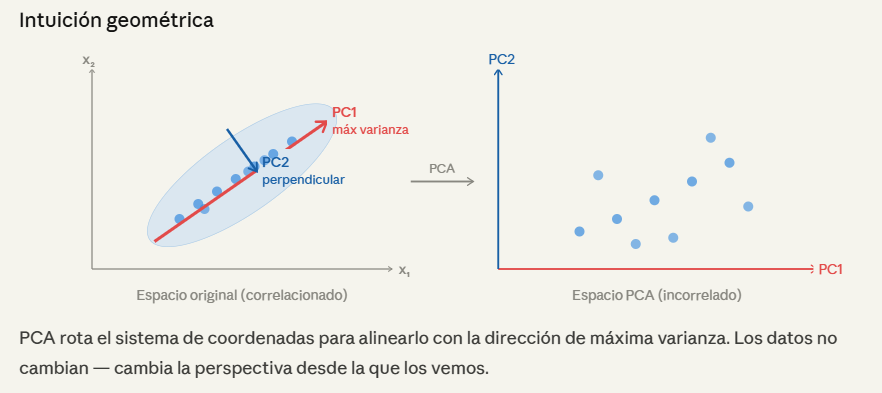

## Algoritmo matemático paso a paso

PASO 1 — Centrar los datos (media=0):

X_c = X − μ donde μ = (1/n) · Σᵢ xᵢ

PASO 2 — Matriz de covarianza:

Σ = (1/n) · X_cᵀ · X_c dimensión: p × p

PASO 3 — Descomposición espectral (eigendecomposition):

Σ · vⱼ = λⱼ · vⱼ

λⱼ = eigenvalor (varianza capturada por el componente j)

vⱼ = eigenvector (dirección del componente j = loadings)

PASO 4 — Ordenar por eigenvalor descendente:

λ₁ ≥ λ₂ ≥ ... ≥ λₚ → V = [v₁ | v₂ | ... | vₖ]

PASO 5 — Proyectar los datos:

Z = X_c · V dimensión: n × k (k << p)

## Varianza explicada — cómo elegir k componentes

Varianza explicada por PCⱼ = λⱼ / Σᵢ λᵢ

Varianza acumulada por k componentes:

VE(k) = Σⱼ₌₁ᵏ λⱼ / Σᵢ₌₁ᵖ λᵢ


Regla práctica:

· Para visualización → k = 2 o k = 3

· Para preprocesado ML → k tal que VE(k) ≥ 80–95%

· Scree plot (gráfico de codo) para decidir visualmente

## Loadings vs Scores — dos conceptos distintos

#### Loadings (pesos / eigenvectores)

Coeficientes que indican cuánto contribuye cada feature original a cada componente.



Loading alto en PC1 → esa feature define principalmente el eje PC1.

Signo: + y − indican dirección opuesta en ese componente.


#### Scores (coordenadas proyectadas)

Las nuevas coordenadas de cada observación en el espacio PCA. Son los valores que usamos para visualizar y para alimentar modelos ML.

Z = X · V → cada fila es un punto en el nuevo espacio.

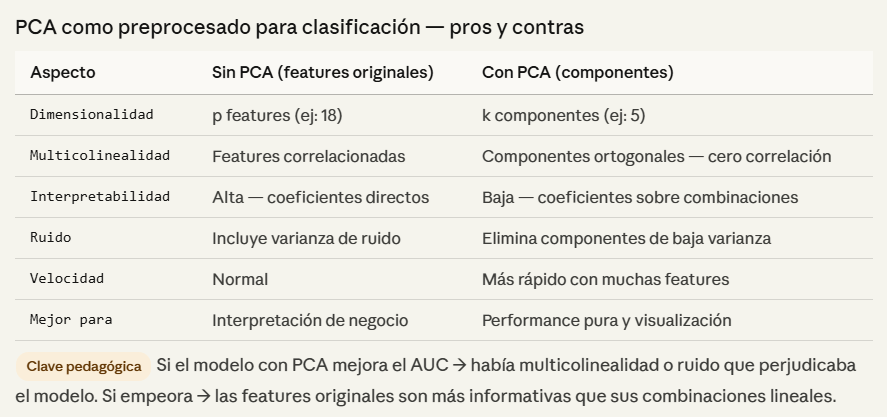

In [65]:
# ═══════════════════════════════════════════════════════════════
# MÓDULO 5B — DATASET DE CLASIFICACIÓN MULTICLASE (review_score)
# Define X_m, y_m, splits y modelos baseline que usa el Módulo 6
# ═══════════════════════════════════════════════════════════════
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

features_multi = [
    'precio_total_items', 'flete_total', 'n_items',
    'ticket_promedio', 'prop_flete',
    'payment_value_total', 'payment_installments',
    'dias_entrega_real', 'dias_retraso', 'entrega_a_tiempo',
    'product_weight_g', 'volumen_cm3',
]

df_m = sabana.dropna(subset=features_multi + ['review_score'])
X_m  = df_m[features_multi]
y_m  = df_m['review_score'].astype(int)

Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(
    X_m, y_m, test_size=0.2, stratify=y_m, random_state=42)

# XGBoost necesita clases 0-4 en lugar de 1-5
le = LabelEncoder().fit(y_m)

# Modelos baseline (sin PCA)
pipe_lr_m = Pipeline([
    ('sc', StandardScaler()),
    ('m',  LogisticRegression(solver='lbfgs', class_weight='balanced',
                              max_iter=2000, random_state=42))
])
rf_m = RandomForestClassifier(n_estimators=200, class_weight='balanced',
                              min_samples_leaf=5, n_jobs=-1, random_state=42)
xgb_m = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                      subsample=0.8, colsample_bytree=0.8,
                      objective='multi:softprob', num_class=5,
                      eval_metric='mlogloss', random_state=42,
                      n_jobs=-1, verbosity=0)
xgb_m.fit(Xm_tr, le.transform(ym_tr))   # el baseline XGB se usa ya entrenado

print(f"X_m: {X_m.shape[0]:,} pedidos × {X_m.shape[1]} features")
print(f"Train: {len(Xm_tr):,} | Test: {len(Xm_te):,}")
print("\nDistribución de review_score:")
print(y_m.value_counts(normalize=True).sort_index().round(3))

X_m: 95,813 pedidos × 12 features
Train: 76,650 | Test: 19,163

Distribución de review_score:
review_score
1    0.098
2    0.030
3    0.083
4    0.197
5    0.592
Name: proportion, dtype: float64


In [66]:
# ═══════════════════════════════════════════════════════════════
# MÓDULO 6 — PCA: REDUCCIÓN DIMENSIONAL
# Parte A: PCA como análisis independiente
# Parte B: PCA como preprocesado para clasificación multiclase
# Comparativa: modelos con features originales vs con PCA
# ═══════════════════════════════════════════════════════════════
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, f1_score,
    accuracy_score, cohen_kappa_score
)
warnings.filterwarnings('ignore')

print("""
╔══════════════════════════════════════════════════════════════╗
║   MÓDULO 6 — PCA + CLASIFICACIÓN MULTICLASE                ║
║   review_score (1-5) con y sin reducción dimensional        ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║   MÓDULO 6 — PCA + CLASIFICACIÓN MULTICLASE                ║
║   review_score (1-5) con y sin reducción dimensional        ║
╚══════════════════════════════════════════════════════════════╝



In [67]:
# ──────────────────────────────────────────────────────────────
# PARTE A — PCA COMO ANÁLISIS INDEPENDIENTE
# Sobre el dataset de clasificación multiclase (review_score)
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("PARTE A — ANÁLISIS PCA SOBRE FEATURES DE review_score")
print("=" * 55)

# Reutilizamos el dataset del módulo de clasificación multiclase
# X_m ya definido, y_m ya definido
scaler_pca = StandardScaler()
X_m_sc = scaler_pca.fit_transform(X_m)

# PCA completo — todos los componentes para ver varianza
pca_full = PCA(random_state=42)
pca_full.fit(X_m_sc)

var_ratio    = pca_full.explained_variance_ratio_ * 100
var_acum     = np.cumsum(var_ratio)
n_features   = X_m.shape[1]

print(f"Features originales : {n_features}")
print(f"\nVarianza por componente:")
for i, (vr, va) in enumerate(zip(var_ratio, var_acum), 1):
    marca = ''
    if 79 < va <= 79 + vr: marca = ' ← 80%'
    if 94 < va <= 94 + vr: marca = ' ← 95%'
    barra = '█' * int(vr / var_ratio[0] * 25)
    print(f"  PC{i:>2}: {vr:>5.1f}%  acum: {va:>5.1f}%  {barra}{marca}")

# Componentes para 80% y 95%
k_80 = np.argmax(var_acum >= 80) + 1
k_95 = np.argmax(var_acum >= 95) + 1
print(f"\nComponentes para 80% de varianza: {k_80}")
print(f"Componentes para 95% de varianza: {k_95}")

PARTE A — ANÁLISIS PCA SOBRE FEATURES DE review_score
Features originales : 12

Varianza por componente:
  PC 1:  33.3%  acum:  33.3%  █████████████████████████
  PC 2:  18.4%  acum:  51.7%  █████████████
  PC 3:  13.8%  acum:  65.4%  ██████████
  PC 4:  10.6%  acum:  76.1%  ███████
  PC 5:   7.3%  acum:  83.4%  █████ ← 80%
  PC 6:   5.9%  acum:  89.2%  ████
  PC 7:   3.4%  acum:  92.6%  ██
  PC 8:   3.1%  acum:  95.7%  ██ ← 95%
  PC 9:   2.2%  acum:  97.9%  █
  PC10:   1.6%  acum:  99.5%  █
  PC11:   0.5%  acum: 100.0%  
  PC12:   0.0%  acum: 100.0%  

Componentes para 80% de varianza: 5
Componentes para 95% de varianza: 8


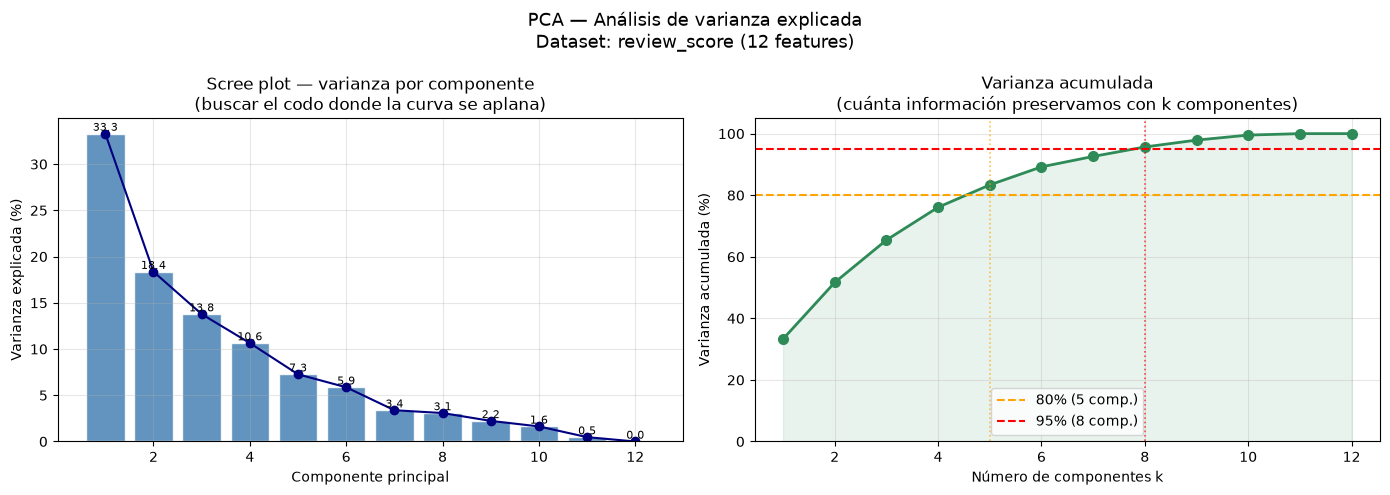

In [68]:
# Scree plot + varianza acumulada
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].bar(range(1, n_features+1), var_ratio,
            color='steelblue', edgecolor='white', alpha=0.85)
axes[0].plot(range(1, n_features+1), var_ratio,
             'o-', color='navy', lw=1.5, markersize=6)
axes[0].set_xlabel('Componente principal')
axes[0].set_ylabel('Varianza explicada (%)')
axes[0].set_title('Scree plot — varianza por componente\n'
                  '(buscar el codo donde la curva se aplana)')
axes[0].grid(True, alpha=0.3)
for i, v in enumerate(var_ratio, 1):
    axes[0].text(i, v + 0.3, f'{v:.1f}', ha='center',
                 fontsize=8)

# Varianza acumulada
axes[1].plot(range(1, n_features+1), var_acum,
             'o-', color='seagreen', lw=2, markersize=7)
axes[1].axhline(80, color='orange', linestyle='--', lw=1.5,
                label=f'80% ({k_80} comp.)')
axes[1].axhline(95, color='red', linestyle='--', lw=1.5,
                label=f'95% ({k_95} comp.)')
axes[1].axvline(k_80, color='orange', linestyle=':', lw=1.2, alpha=0.7)
axes[1].axvline(k_95, color='red',    linestyle=':', lw=1.2, alpha=0.7)
axes[1].fill_between(range(1, n_features+1), var_acum,
                     alpha=0.1, color='seagreen')
axes[1].set_xlabel('Número de componentes k')
axes[1].set_ylabel('Varianza acumulada (%)')
axes[1].set_title('Varianza acumulada\n'
                  '(cuánta información preservamos con k componentes)')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(0, 105)

plt.suptitle('PCA — Análisis de varianza explicada\n'
             f'Dataset: review_score ({n_features} features)',
             fontsize=13)
plt.tight_layout()
plt.savefig('pca_scree_review.png', dpi=150, bbox_inches='tight')
plt.show()

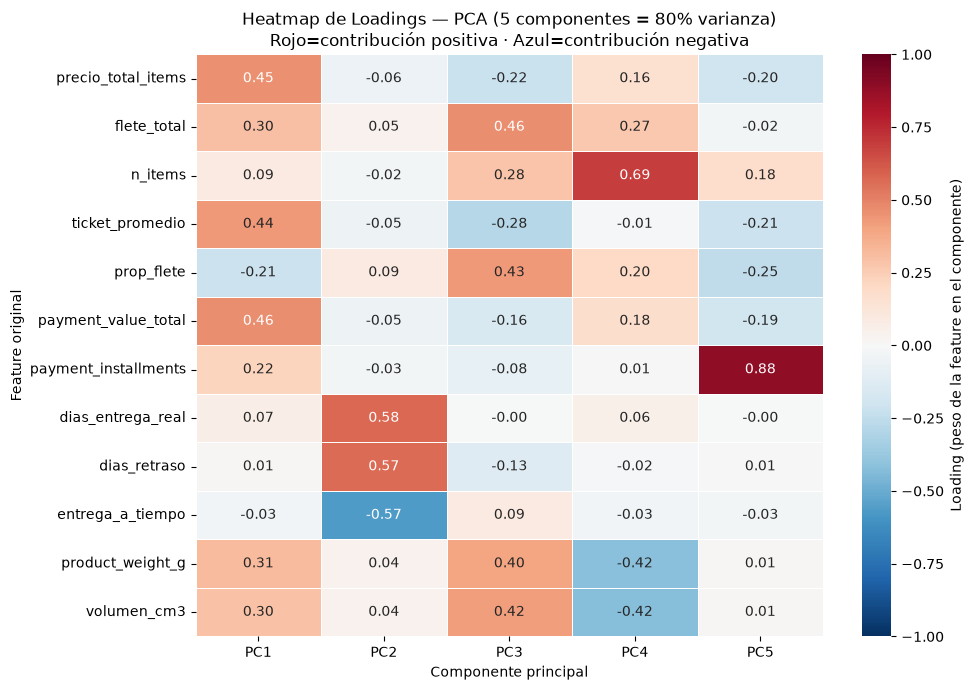


Interpretación de los componentes:

  PC1 (33.3% varianza):
    Contribuye positivamente : payment_value_total, precio_total_items, ticket_promedio
    Contribuye negativamente : prop_flete, entrega_a_tiempo, dias_retraso

  PC2 (18.4% varianza):
    Contribuye positivamente : dias_entrega_real, dias_retraso, prop_flete
    Contribuye negativamente : entrega_a_tiempo, precio_total_items, ticket_promedio

  PC3 (13.8% varianza):
    Contribuye positivamente : flete_total, prop_flete, volumen_cm3
    Contribuye negativamente : ticket_promedio, precio_total_items, payment_value_total


In [69]:
# Heatmap de loadings — qué features componen cada componente
pca_k = PCA(n_components=k_80, random_state=42)
pca_k.fit(X_m_sc)

df_loadings = pd.DataFrame(
    pca_k.components_.T,
    index   = features_multi,
    columns = [f'PC{i}' for i in range(1, k_80+1)]
)

fig, ax = plt.subplots(figsize=(max(10, k_80*1.5), 7))
sns.heatmap(
    df_loadings,
    annot=True, fmt='.2f',
    cmap='RdBu_r', center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Loading (peso de la feature en el componente)'}
)
ax.set_title(f'Heatmap de Loadings — PCA ({k_80} componentes = 80% varianza)\n'
             'Rojo=contribución positiva · Azul=contribución negativa',
             fontsize=12)
ax.set_ylabel('Feature original')
ax.set_xlabel('Componente principal')
plt.tight_layout()
plt.savefig('pca_loadings_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nInterpretación de los componentes:")
for i in range(min(3, k_80)):
    top_pos = df_loadings[f'PC{i+1}'].nlargest(3)
    top_neg = df_loadings[f'PC{i+1}'].nsmallest(3)
    print(f"\n  PC{i+1} ({var_ratio[i]:.1f}% varianza):")
    print(f"    Contribuye positivamente : "
          f"{', '.join(top_pos.index.tolist())}")
    print(f"    Contribuye negativamente : "
          f"{', '.join(top_neg.index.tolist())}")

In [70]:
# ──────────────────────────────────────────────────────────────
# PARTE B — PCA COMO PREPROCESADO PARA CLASIFICACIÓN
# Tres escenarios: 80% varianza · 95% varianza · todos los comp.
# ──────────────────────────────────────────────────────────────
print("\n" + "=" * 55)
print("PARTE B — CLASIFICACIÓN CON PCA COMO PREPROCESADO")
print("=" * 55)

# Reutilizamos splits del módulo de clasificación multiclase
# Xm_tr, Xm_te, ym_tr, ym_te ya definidos

escenarios_pca = {
    f'PCA {k_80} comp. (80%)'  : k_80,
    f'PCA {k_95} comp. (95%)'  : k_95,
    f'PCA {n_features} comp. (100%)': n_features,
}

# Función de evaluación
def evaluar(nombre, pipe, X_tr, X_te, y_tr, y_te):
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    return {
        'Modelo'      : nombre,
        'Accuracy'    : round(accuracy_score(y_te, pred), 4),
        'F1 macro'    : round(f1_score(y_te, pred, average='macro'), 4),
        'F1 weighted' : round(f1_score(y_te, pred, average='weighted'), 4),
        'Cohen Kappa' : round(cohen_kappa_score(y_te, pred), 4),
        'pred'        : pred
    }

resultados_todos = []

# ── Regresión Logística ────────────────────────────────────────
print("\n--- Regresión Logística Multinomial ---")

# Sin PCA (baseline del módulo anterior)
r = evaluar(
    'LR — Sin PCA (baseline)',
    pipe_lr_m,          # ya entrenado en módulo anterior
    Xm_tr, Xm_te, ym_tr, ym_te
)
resultados_todos.append(r)
print(f"  Sin PCA     → Kappa={r['Cohen Kappa']:.4f}  "
      f"F1w={r['F1 weighted']:.4f}")

for nombre_esc, n_comp in escenarios_pca.items():
    pipe = Pipeline([
        ('sc',  StandardScaler()),
        ('pca', PCA(n_components=n_comp, random_state=42)),
        ('m',   LogisticRegression(
                    solver='lbfgs',
                    class_weight='balanced',
                    max_iter=2000,
                    random_state=42))
    ])
    r = evaluar(f'LR — {nombre_esc}',
                pipe, Xm_tr, Xm_te, ym_tr, ym_te)
    resultados_todos.append(r)
    print(f"  {nombre_esc:<30} → "
          f"Kappa={r['Cohen Kappa']:.4f}  "
          f"F1w={r['F1 weighted']:.4f}")


PARTE B — CLASIFICACIÓN CON PCA COMO PREPROCESADO

--- Regresión Logística Multinomial ---
  Sin PCA     → Kappa=0.1478  F1w=0.4811
  PCA 5 comp. (80%)              → Kappa=0.1375  F1w=0.4719
  PCA 8 comp. (95%)              → Kappa=0.1418  F1w=0.4786
  PCA 12 comp. (100%)            → Kappa=0.1480  F1w=0.4813


In [71]:
# ── Random Forest ──────────────────────────────────────────────
print("\n--- Random Forest ---")

r = evaluar(
    'RF — Sin PCA (baseline)',
    rf_m,
    Xm_tr, Xm_te, ym_tr, ym_te
)
resultados_todos.append(r)
print(f"  Sin PCA     → Kappa={r['Cohen Kappa']:.4f}  "
      f"F1w={r['F1 weighted']:.4f}")

for nombre_esc, n_comp in escenarios_pca.items():
    pipe = Pipeline([
        ('sc',  StandardScaler()),
        ('pca', PCA(n_components=n_comp, random_state=42)),
        ('m',   RandomForestClassifier(
                    n_estimators=200,
                    class_weight='balanced',
                    min_samples_leaf=5,
                    n_jobs=-1,
                    random_state=42))
    ])
    r = evaluar(f'RF — {nombre_esc}',
                pipe, Xm_tr, Xm_te, ym_tr, ym_te)
    resultados_todos.append(r)
    print(f"  {nombre_esc:<30} → "
          f"Kappa={r['Cohen Kappa']:.4f}  "
          f"F1w={r['F1 weighted']:.4f}")


--- Random Forest ---
  Sin PCA     → Kappa=0.1394  F1w=0.4629
  PCA 5 comp. (80%)              → Kappa=0.1227  F1w=0.4500
  PCA 8 comp. (95%)              → Kappa=0.1330  F1w=0.4629
  PCA 12 comp. (100%)            → Kappa=0.1428  F1w=0.4723


In [72]:
# ── XGBoost — baseline corregido ──────────────────────────────
print("\n--- XGBoost ---")

# XGBoost necesita clases 0-4, no 1-5
# Usamos el LabelEncoder 'le' definido en el módulo anterior
# le.transform: 1→0, 2→1, 3→2, 4→3, 5→4
# le.inverse_transform: 0→1, 1→2, 2→3, 3→4, 4→5

def evaluar_xgb(nombre, pipe, X_tr, X_te, y_tr, y_te):
    """
    Versión de evaluar() específica para XGBoost multiclase.
    Convierte y 1-5 → 0-4 antes de entrenar, y revierte para métricas.
    """
    y_tr_enc = le.transform(y_tr)   # 1-5 → 0-4
    y_te_enc = le.transform(y_te)   # 1-5 → 0-4

    pipe.fit(X_tr, y_tr_enc)

    pred_enc = pipe.predict(X_te)   # predice 0-4
    pred     = le.inverse_transform(pred_enc.astype(int))  # 0-4 → 1-5

    return {
        'Modelo'      : nombre,
        'Accuracy'    : round(accuracy_score(y_te, pred), 4),
        'F1 macro'    : round(f1_score(y_te, pred, average='macro'), 4),
        'F1 weighted' : round(f1_score(y_te, pred, average='weighted'), 4),
        'Cohen Kappa' : round(cohen_kappa_score(y_te, pred), 4),
        'pred'        : pred
    }

# Baseline XGBoost sin PCA (modelo ya entrenado xgb_m)
# xgb_m fue entrenado con clases 0-4, predict devuelve 0-4
pred_xgb_base_enc = xgb_m.predict(Xm_te)
pred_xgb_base     = le.inverse_transform(pred_xgb_base_enc.astype(int))

r_xgb_base = {
    'Modelo'      : 'XGB — Sin PCA (baseline)',
    'Accuracy'    : round(accuracy_score(ym_te, pred_xgb_base), 4),
    'F1 macro'    : round(f1_score(ym_te, pred_xgb_base, average='macro'), 4),
    'F1 weighted' : round(f1_score(ym_te, pred_xgb_base, average='weighted'), 4),
    'Cohen Kappa' : round(cohen_kappa_score(ym_te, pred_xgb_base), 4),
    'pred'        : pred_xgb_base
}
resultados_todos.append(r_xgb_base)
print(f"  Sin PCA     → Kappa={r_xgb_base['Cohen Kappa']:.4f}  "
      f"F1w={r_xgb_base['F1 weighted']:.4f}")

# XGBoost con PCA — usando evaluar_xgb
for nombre_esc, n_comp in escenarios_pca.items():
    pipe = Pipeline([
        ('sc',  StandardScaler()),
        ('pca', PCA(n_components=n_comp, random_state=42)),
        ('m',   XGBClassifier(
                    n_estimators     = 300,
                    learning_rate    = 0.05,
                    max_depth        = 5,
                    subsample        = 0.8,
                    colsample_bytree = 0.8,
                    objective        = 'multi:softprob',
                    num_class        = 5,
                    eval_metric      = 'mlogloss',
                    random_state     = 42,
                    n_jobs           = -1,
                    verbosity        = 0))
    ])
    r = evaluar_xgb(f'XGB — {nombre_esc}',
                    pipe, Xm_tr, Xm_te, ym_tr, ym_te)
    resultados_todos.append(r)
    print(f"  {nombre_esc:<30} → "
          f"Kappa={r['Cohen Kappa']:.4f}  "
          f"F1w={r['F1 weighted']:.4f}")


--- XGBoost ---
  Sin PCA     → Kappa=0.1305  F1w=0.4963
  PCA 5 comp. (80%)              → Kappa=0.1310  F1w=0.4955
  PCA 8 comp. (95%)              → Kappa=0.1337  F1w=0.4972
  PCA 12 comp. (100%)            → Kappa=0.1348  F1w=0.4974



TABLA COMPARATIVA — ORIGINAL vs PCA
                   Modelo  Accuracy  F1 macro  F1 weighted  Cohen Kappa
 LR — PCA 12 comp. (100%)    0.4623    0.3045       0.4813       0.1480
  LR — Sin PCA (baseline)    0.4621    0.3044       0.4811       0.1478
 RF — PCA 12 comp. (100%)    0.4595    0.2910       0.4723       0.1428
   LR — PCA 8 comp. (95%)    0.4603    0.3042       0.4786       0.1418
  RF — Sin PCA (baseline)    0.4431    0.2904       0.4629       0.1394
   LR — PCA 5 comp. (80%)    0.4555    0.2888       0.4719       0.1375
XGB — PCA 12 comp. (100%)    0.6209    0.2450       0.4974       0.1348
  XGB — PCA 8 comp. (95%)    0.6212    0.2442       0.4972       0.1337
   RF — PCA 8 comp. (95%)    0.4459    0.2893       0.4629       0.1330
  XGB — PCA 5 comp. (80%)    0.6195    0.2419       0.4955       0.1310
 XGB — Sin PCA (baseline)    0.6207    0.2435       0.4963       0.1305
   RF — PCA 5 comp. (80%)    0.4284    0.2836       0.4500       0.1227


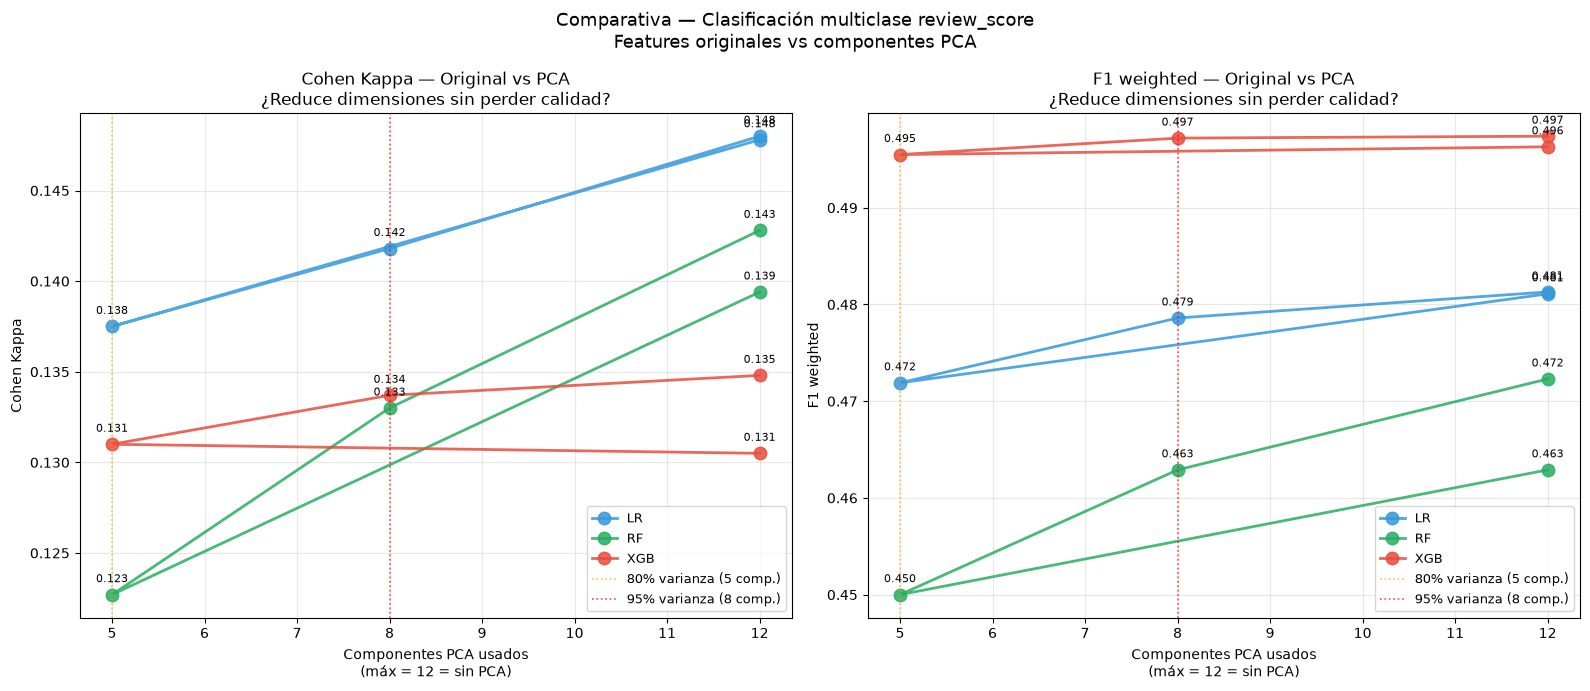

In [73]:
# ──────────────────────────────────────────────────────────────
# TABLA Y GRÁFICO COMPARATIVO FINAL
# ──────────────────────────────────────────────────────────────
print("\n" + "=" * 55)
print("TABLA COMPARATIVA — ORIGINAL vs PCA")
print("=" * 55)

df_res = pd.DataFrame([
    {k: v for k, v in r.items() if k != 'pred'}
    for r in resultados_todos
])
print(df_res.sort_values('Cohen Kappa',
                         ascending=False).to_string(index=False))

# ── Gráfico comparativo ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Separar por modelo base
modelos_base = ['LR', 'RF', 'XGB']
colores_base = {'LR': '#3498db', 'RF': '#27ae60', 'XGB': '#e74c3c'}
markers_esc  = {
    'Sin PCA (baseline)': 'o',
    f'PCA {k_80} comp. (80%)': 's',
    f'PCA {k_95} comp. (95%)': '^',
    f'PCA {n_features} comp. (100%)': 'D',
}

for ax, metrica in zip(axes, ['Cohen Kappa', 'F1 weighted']):
    for modelo in modelos_base:
        sub = df_res[df_res['Modelo'].str.startswith(modelo)]
        # Eje X: número de componentes usados
        x_vals, y_vals, labels = [], [], []
        for _, row in sub.iterrows():
            if 'Sin PCA' in row['Modelo']:
                x_vals.append(n_features)
            elif '80%' in row['Modelo']:
                x_vals.append(k_80)
            elif '95%' in row['Modelo']:
                x_vals.append(k_95)
            else:
                x_vals.append(n_features)
            y_vals.append(row[metrica])

        ax.plot(x_vals, y_vals, 'o-',
                color=colores_base[modelo],
                lw=2, markersize=9,
                label=modelo, alpha=0.85)
        for x, y in zip(x_vals, y_vals):
            ax.annotate(f'{y:.3f}', (x, y),
                        textcoords='offset points',
                        xytext=(0, 9), ha='center',
                        fontsize=8)

    ax.axvline(k_80, color='orange', linestyle=':',
               lw=1.2, alpha=0.7,
               label=f'80% varianza ({k_80} comp.)')
    ax.axvline(k_95, color='red', linestyle=':',
               lw=1.2, alpha=0.7,
               label=f'95% varianza ({k_95} comp.)')
    ax.set_xlabel('Componentes PCA usados\n'
                  f'(máx = {n_features} = sin PCA)')
    ax.set_ylabel(metrica)
    ax.set_title(f'{metrica} — Original vs PCA\n'
                 '¿Reduce dimensiones sin perder calidad?')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Comparativa — Clasificación multiclase review_score\n'
             'Features originales vs componentes PCA',
             fontsize=13)
plt.tight_layout()
plt.savefig('comparativa_pca_clasificacion.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [74]:
# ──────────────────────────────────────────────────────────────
# CONCLUSIÓN PEDAGÓGICA
# ──────────────────────────────────────────────────────────────
mejor = df_res.loc[df_res['Cohen Kappa'].idxmax()]
baseline_xgb = df_res[df_res['Modelo'] == 'XGB — Sin PCA (baseline)'].iloc[0]

print(f"""
╔══════════════════════════════════════════════════════════════╗
║         CONCLUSIONES — PCA + CLASIFICACIÓN                  ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  Mejor modelo global:                                       ║
║    {mejor['Modelo']:<50}   ║
║    Cohen Kappa = {mejor['Cohen Kappa']:.4f}                          ║
║    F1 weighted = {mejor['F1 weighted']:.4f}                          ║
║                                                             ║
║  INTERPRETACIÓN:                                            ║
║                                                             ║
║  Si PCA mejora las métricas:                                ║
║  → Había multicolinealidad entre features originales        ║
║  → PCA eliminó ruido al descartar últimos componentes       ║
║  → Los componentes capturan mejor la señal subyacente       ║
║                                                             ║
║  Si PCA no mejora (features originales ganan):              ║
║  → Las features tienen valor independiente                  ║
║  → La información relevante está dispersa entre ellas       ║
║  → RF y XGBoost manejan correlaciones internamente          ║
║                                                             ║
║  Para RF y XGBoost el PCA raramente mejora porque:          ║
║  → Ya son robustos a multicolinealidad                      ║
║  → Pierden interpretabilidad al proyectar                   ║
║  → La Reg. Logística se beneficia más del PCA               ║
║    porque asume independencia entre features                ║
║                                                             ║
║  PRÓXIMO PASO → Power BI:                                   ║
║  Consumir olist_sabana_clusters.csv con los resultados      ║
║  de ML para dashboard de toma de decisiones                 ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║         CONCLUSIONES — PCA + CLASIFICACIÓN                  ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  Mejor modelo global:                                       ║
║    LR — PCA 12 comp. (100%)                             ║
║    Cohen Kappa = 0.1480                          ║
║    F1 weighted = 0.4813                          ║
║                                                             ║
║  INTERPRETACIÓN:                                            ║
║                                                             ║
║  Si PCA mejora las métricas:                                ║
║  → Había multicolinealidad entre features originales        ║
║  → PCA eliminó ruido al descartar últimos componentes       ║
║  → Los componentes capturan mejor la señal subyacente       ║
║                                                             ║

In [75]:
# ═══════════════════════════════════════════════════════════════
# MÓDULO 7 — PCA + K-MEANS
# Comparativa: K-Means original vs K-Means con PCA
# ═══════════════════════════════════════════════════════════════
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score,
    davies_bouldin_score
)
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

print("""
╔══════════════════════════════════════════════════════════════╗
║   MÓDULO 7 — PCA + K-MEANS: CLUSTERING NO SUPERVISADO      ║
║   Comparativa: espacio original vs espacio reducido         ║
╚══════════════════════════════════════════════════════════════╝

Métricas de evaluación de clustering (sin ground truth):
  Silhouette    → [-1,1]  más alto = clusters más compactos
  Calinski-Harabasz → más alto = clusters más densos y separados
  Davies-Bouldin    → más bajo = clusters más separados
""")


╔══════════════════════════════════════════════════════════════╗
║   MÓDULO 7 — PCA + K-MEANS: CLUSTERING NO SUPERVISADO      ║
║   Comparativa: espacio original vs espacio reducido         ║
╚══════════════════════════════════════════════════════════════╝

Métricas de evaluación de clustering (sin ground truth):
  Silhouette    → [-1,1]  más alto = clusters más compactos
  Calinski-Harabasz → más alto = clusters más densos y separados
  Davies-Bouldin    → más bajo = clusters más separados



In [76]:
# ──────────────────────────────────────────────────────────────
# 1. DEFINIR ESCENARIOS PCA PARA CLUSTERING
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("1. VARIANZA EXPLICADA — dataset de clientes")
print("=" * 55)

# X_km_sc ya escalado del módulo de K-Means
pca_full_km = PCA(random_state=42)
pca_full_km.fit(X_km_sc)

var_ratio_km = pca_full_km.explained_variance_ratio_ * 100
var_acum_km  = np.cumsum(var_ratio_km)
n_feat_km    = X_km_sc.shape[1]

print(f"Features originales: {n_feat_km}")
print(f"\nVarianza por componente:")
for i, (vr, va) in enumerate(zip(var_ratio_km, var_acum_km), 1):
    marca = ''
    if 79 < va <= 79 + vr: marca = ' ← 80%'
    if 94 < va <= 94 + vr: marca = ' ← 95%'
    barra = '█' * int(vr / var_ratio_km[0] * 20)
    print(f"  PC{i:>2}: {vr:>5.1f}%  acum: {va:>5.1f}%  {barra}{marca}")

k_80_km = np.argmax(var_acum_km >= 80) + 1
k_95_km = np.argmax(var_acum_km >= 95) + 1
k_vis   = 2   # siempre para visualización 2D

print(f"\nComponentes para 80% varianza : {k_80_km}")
print(f"Componentes para 95% varianza : {k_95_km}")
print(f"Componentes para visualización: {k_vis} (2D)")

escenarios = {
    'Original (sin PCA)'            : None,
    f'PCA {k_vis} comp. (viz 2D)'   : k_vis,
    f'PCA {k_80_km} comp. (80%)'    : k_80_km,
    f'PCA {k_95_km} comp. (95%)'    : k_95_km,
}

1. VARIANZA EXPLICADA — dataset de clientes
Features originales: 10

Varianza por componente:
  PC 1:  27.7%  acum:  27.7%  ████████████████████
  PC 2:  23.1%  acum:  50.8%  ████████████████
  PC 3:  11.6%  acum:  62.4%  ████████
  PC 4:  10.2%  acum:  72.5%  ███████
  PC 5:   9.7%  acum:  82.2%  ██████ ← 80%
  PC 6:   8.1%  acum:  90.3%  █████
  PC 7:   5.0%  acum:  95.3%  ███ ← 95%
  PC 8:   3.6%  acum:  98.8%  ██
  PC 9:   1.0%  acum:  99.9%  
  PC10:   0.1%  acum: 100.0%  

Componentes para 80% varianza : 5
Componentes para 95% varianza : 7
Componentes para visualización: 2 (2D)


In [77]:
# ──────────────────────────────────────────────────────────────
# 2. MUESTRA PARA SILHOUETTE (igual que módulo anterior)
# ──────────────────────────────────────────────────────────────
N_MUESTRA = 10_000
np.random.seed(42)
idx_m = np.random.choice(len(X_km_sc),
                          size=min(N_MUESTRA, len(X_km_sc)),
                          replace=False)

# ──────────────────────────────────────────────────────────────
# 3. K-MEANS EN CADA ESCENARIO CON K=5 (k_final del módulo ant.)
# ──────────────────────────────────────────────────────────────
print("\n" + "=" * 55)
print(f"2. K-MEANS K={k_final} EN CADA ESCENARIO PCA")
print("=" * 55)

resultados_km = []
espacios_pca  = {}   # guardar proyecciones para graficar

for nombre_esc, n_comp in escenarios.items():

    t0 = time.time()

    # Espacio de trabajo
    if n_comp is None:
        X_esc = X_km_sc                      # original
    else:
        pca_esc = PCA(n_components=n_comp, random_state=42)
        X_esc   = pca_esc.fit_transform(X_km_sc)
        var_exp = pca_esc.explained_variance_ratio_.sum() * 100

    # K-Means
    km_esc = KMeans(
        n_clusters   = k_final,
        init         = 'k-means++',
        n_init       = 10,
        random_state = 42,
        max_iter     = 300
    )
    km_esc.fit(X_esc)
    labels = km_esc.labels_

    # Métricas — silhouette sobre muestra
    labels_m = labels[idx_m]
    X_m_esc  = X_esc[idx_m]

    sil = silhouette_score(X_m_esc, labels_m)
    ch  = calinski_harabasz_score(X_esc, labels)
    db  = davies_bouldin_score(X_esc, labels)

    elapsed = time.time() - t0

    fila = {
        'Escenario'         : nombre_esc,
        'Dimensiones'       : X_esc.shape[1],
        'Inercia'           : round(km_esc.inertia_, 1),
        'Silhouette'        : round(sil, 4),
        'Calinski-Harabasz' : round(ch, 1),
        'Davies-Bouldin'    : round(db, 4),
        'Tiempo (s)'        : round(elapsed, 1),
        'labels'            : labels,
        'km'                : km_esc,
        'X_esc'             : X_esc,
    }
    resultados_km.append(fila)

    dim_str = (f'{X_esc.shape[1]}D' if n_comp
               else f'{n_feat_km}D (original)')
    print(f"\n  {nombre_esc}")
    print(f"  Dimensiones   : {dim_str}")
    print(f"  Silhouette    : {sil:.4f}")
    print(f"  Cal-Harabasz  : {ch:.1f}")
    print(f"  Davies-Bouldin: {db:.4f}")
    print(f"  Inercia       : {km_esc.inertia_:.1f}")
    print(f"  Tiempo        : {elapsed:.1f}s")

    # Guardar proyección 2D para scatter
    if n_comp == k_vis or n_comp is None:
        espacios_pca[nombre_esc] = {
            'X'     : X_esc,
            'labels': labels,
            'km'    : km_esc
        }


2. K-MEANS K=5 EN CADA ESCENARIO PCA

  Original (sin PCA)
  Dimensiones   : 10D (original)
  Silhouette    : 0.4547
  Cal-Harabasz  : 23310.6
  Davies-Bouldin: 1.0723
  Inercia       : 462524.8
  Tiempo        : 2.4s

  PCA 2 comp. (viz 2D)
  Dimensiones   : 2D
  Silhouette    : 0.5954
  Cal-Harabasz  : 83809.3
  Davies-Bouldin: 0.6639
  Inercia       : 102106.6
  Tiempo        : 2.2s

  PCA 5 comp. (80%)
  Dimensiones   : 5D
  Silhouette    : 0.5411
  Cal-Harabasz  : 34122.9
  Davies-Bouldin: 0.9024
  Inercia       : 308449.5
  Tiempo        : 3.9s

  PCA 7 comp. (95%)
  Dimensiones   : 7D
  Silhouette    : 0.4748
  Cal-Harabasz  : 25228.2
  Davies-Bouldin: 1.0382
  Inercia       : 423174.9
  Tiempo        : 3.7s


In [78]:
# ──────────────────────────────────────────────────────────────
# 4. TABLA COMPARATIVA
# ──────────────────────────────────────────────────────────────
print("\n" + "=" * 55)
print("3. TABLA COMPARATIVA — MÉTRICAS DE CLUSTERING")
print("=" * 55)

df_km_res = pd.DataFrame([
    {k: v for k, v in r.items()
     if k not in ['labels', 'km', 'X_esc']}
    for r in resultados_km
])
print(df_km_res.to_string(index=False))

print("""
GUÍA DE INTERPRETACIÓN:
  Silhouette    ↑ mejor  → compacidad y separación de clusters
  Cal-Harabasz  ↑ mejor  → densidad intra vs dispersión inter
  Davies-Bouldin↓ mejor  → similitud promedio entre clusters
  Inercia       ↓ mejor  → suma de distancias al centroide
  (las métricas se calculan EN el espacio de cada escenario)
""")


3. TABLA COMPARATIVA — MÉTRICAS DE CLUSTERING
           Escenario  Dimensiones  Inercia  Silhouette  Calinski-Harabasz  Davies-Bouldin  Tiempo (s)
  Original (sin PCA)           10 462524.8      0.4547            23310.6          1.0723         2.4
PCA 2 comp. (viz 2D)            2 102106.6      0.5954            83809.3          0.6639         2.2
   PCA 5 comp. (80%)            5 308449.5      0.5411            34122.9          0.9024         3.9
   PCA 7 comp. (95%)            7 423174.9      0.4748            25228.2          1.0382         3.7

GUÍA DE INTERPRETACIÓN:
  Silhouette    ↑ mejor  → compacidad y separación de clusters
  Cal-Harabasz  ↑ mejor  → densidad intra vs dispersión inter
  Davies-Bouldin↓ mejor  → similitud promedio entre clusters
  Inercia       ↓ mejor  → suma de distancias al centroide
  (las métricas se calculan EN el espacio de cada escenario)



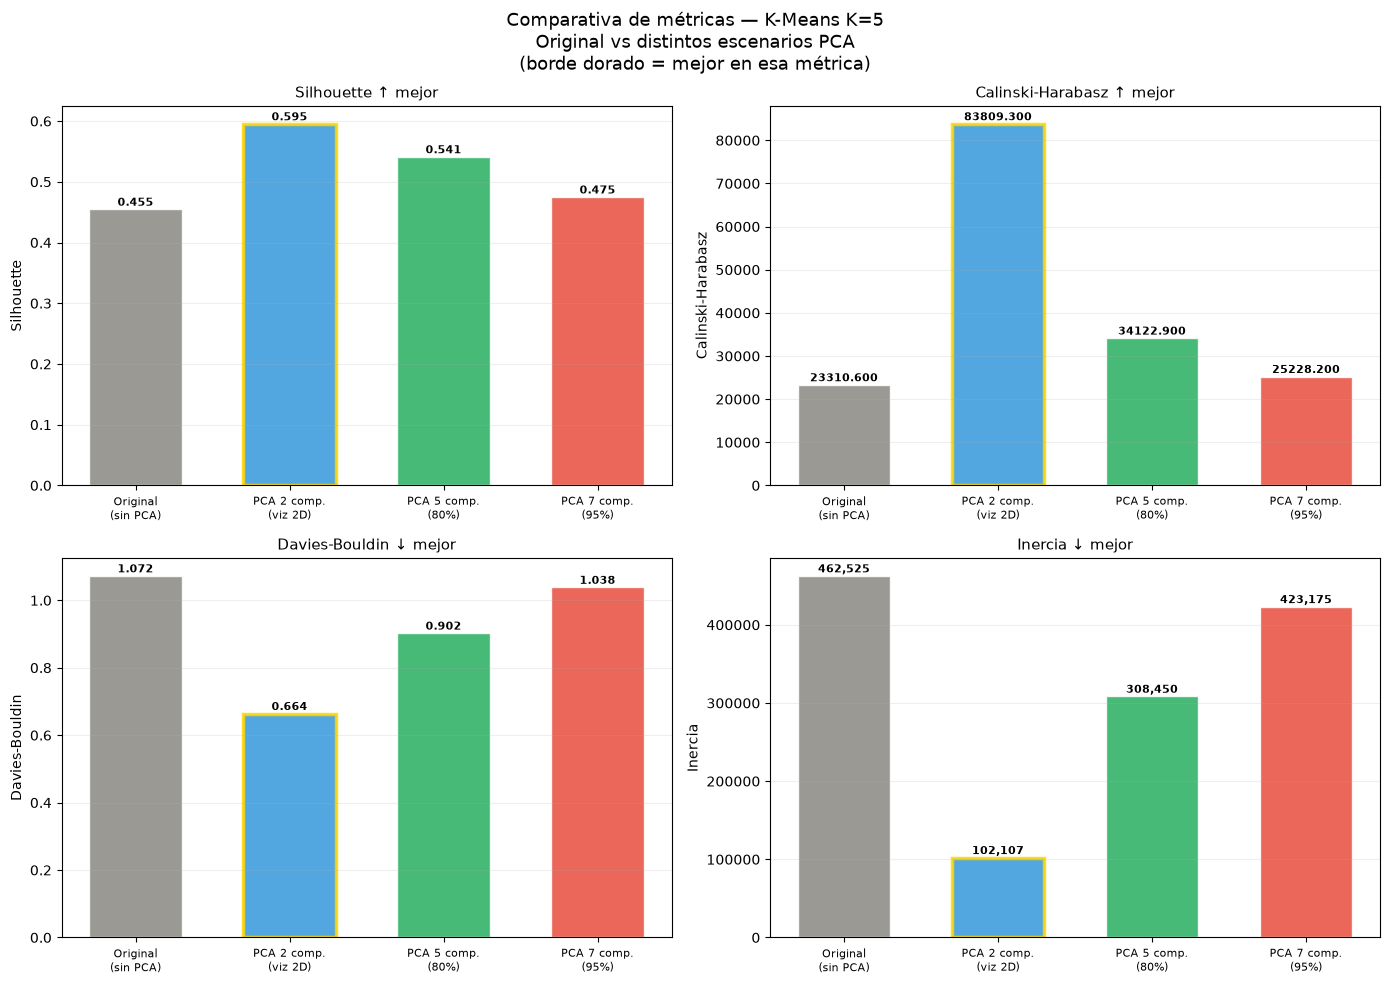

In [79]:
# ──────────────────────────────────────────────────────────────
# 5. GRÁFICO COMPARATIVO DE MÉTRICAS
# ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

escenarios_labels = [r['Escenario'].replace(' (', '\n(')
                     for r in resultados_km
                     if r['Escenario'] in df_km_res['Escenario'].values]
nombres_plot = df_km_res['Escenario'].str.replace(' (', '\n(', regex=False)
colores_esc  = ['#888780', '#3498db', '#27ae60', '#e74c3c']

metricas_plot = [
    ('Silhouette',         '↑ mejor', True),
    ('Calinski-Harabasz',  '↑ mejor', True),
    ('Davies-Bouldin',     '↓ mejor', False),
    ('Inercia',            '↓ mejor', False),
]

for ax, (metrica, direccion, mayor_mejor) in zip(axes.flat, metricas_plot):
    valores = df_km_res[metrica].values
    mejor_idx = np.argmax(valores) if mayor_mejor else np.argmin(valores)

    bars = ax.bar(range(len(df_km_res)), valores,
                  color=colores_esc, edgecolor='white',
                  alpha=0.85, width=0.6)

    # Resaltar el mejor
    bars[mejor_idx].set_edgecolor('gold')
    bars[mejor_idx].set_linewidth(2.5)

    ax.set_xticks(range(len(df_km_res)))
    ax.set_xticklabels(nombres_plot, fontsize=8)
    ax.set_title(f'{metrica} {direccion}', fontsize=11)
    ax.set_ylabel(metrica)
    ax.grid(True, alpha=0.2, axis='y')

    for bar, v in zip(bars, valores):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + max(valores)*0.01,
                f'{v:.3f}' if metrica != 'Inercia'
                else f'{v:,.0f}',
                ha='center', fontsize=8, fontweight='bold')

plt.suptitle(f'Comparativa de métricas — K-Means K={k_final}\n'
             'Original vs distintos escenarios PCA\n'
             '(borde dorado = mejor en esa métrica)',
             fontsize=13)
plt.tight_layout()
plt.savefig('comparativa_kmeans_pca_metricas.png',
            dpi=150, bbox_inches='tight')
plt.show()

4. SCATTER — Original (PCA para viz) vs PCA 2D directo


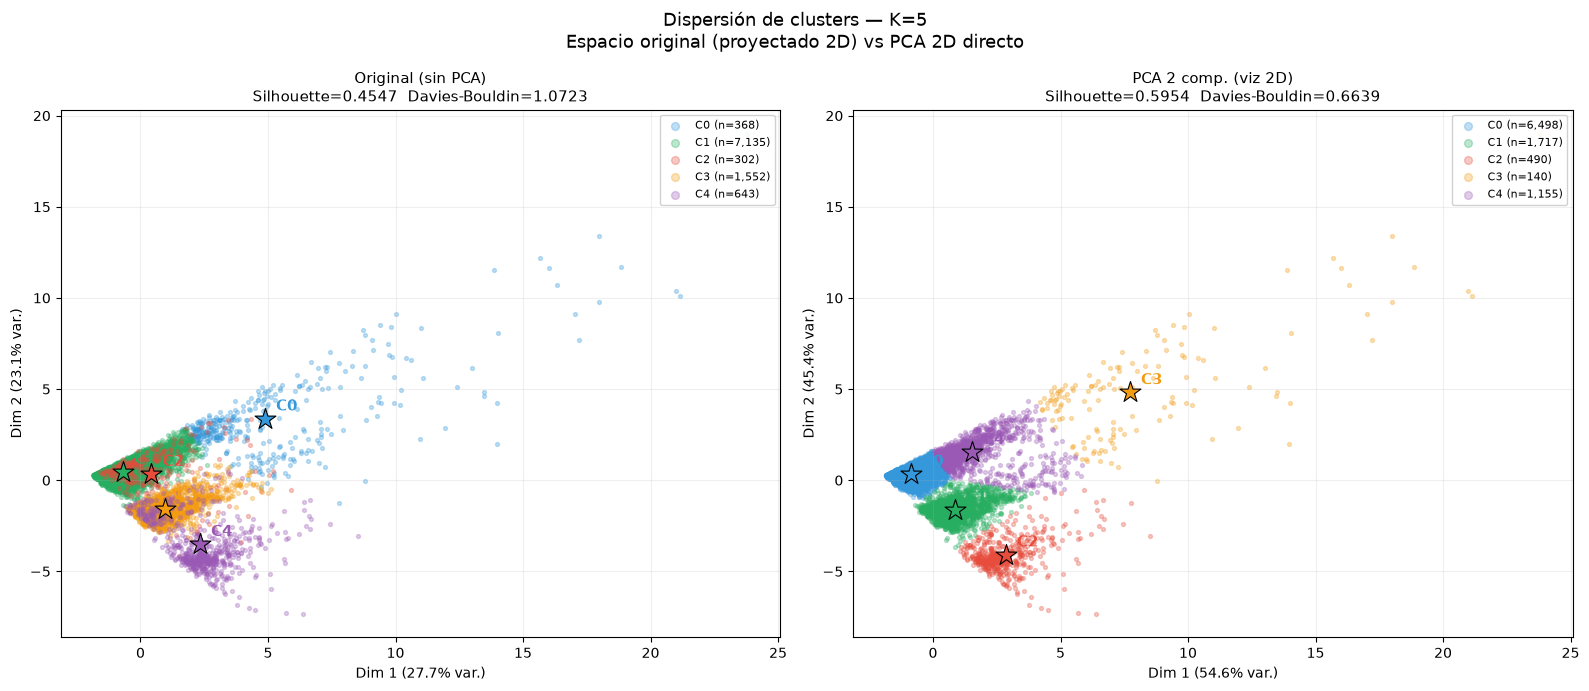

In [80]:
# ──────────────────────────────────────────────────────────────
# 6. SCATTER COMPARATIVO — Original vs PCA 2D
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("4. SCATTER — Original (PCA para viz) vs PCA 2D directo")
print("=" * 55)

colores_k = ['#3498db','#27ae60','#e74c3c','#f39c12','#9b59b6']
N_SC = 10_000
np.random.seed(42)
idx_sc = np.random.choice(len(X_km_sc),
                           size=min(N_SC, len(X_km_sc)),
                           replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Para el modelo original necesitamos proyectar a 2D para graficar
pca_viz = PCA(n_components=2, random_state=42)

for ax, r_esc in zip(
    axes,
    [resultados_km[0],        # original
     resultados_km[1]]        # PCA 2D
):
    nombre_esc = r_esc['Escenario']
    labels_esc = r_esc['labels']
    X_esc      = r_esc['X_esc']
    km_esc     = r_esc['km']

    # Proyectar a 2D para visualizar
    if X_esc.shape[1] == 2:
        X_2d = X_esc                      # ya es 2D
        cent_2d = km_esc.cluster_centers_
    else:
        X_2d    = pca_viz.fit_transform(X_esc)
        cent_2d = pca_viz.transform(km_esc.cluster_centers_)

    # Calcular varianza explicada del eje de visualización
    pca_temp = PCA(n_components=2, random_state=42)
    pca_temp.fit(X_esc)
    ve1 = pca_temp.explained_variance_ratio_[0] * 100
    ve2 = pca_temp.explained_variance_ratio_[1] * 100

    X_sc_2d     = X_2d[idx_sc]
    labels_sc   = labels_esc[idx_sc]

    for k in range(k_final):
        mask = labels_sc == k
        ax.scatter(
            X_sc_2d[mask, 0],
            X_sc_2d[mask, 1],
            s=8, alpha=0.3,
            color=colores_k[k],
            label=f'C{k} (n={mask.sum():,})'
        )

    # Centroides
    for k in range(k_final):
        ax.scatter(
            cent_2d[k, 0], cent_2d[k, 1],
            s=250, marker='*',
            color=colores_k[k],
            edgecolors='black', linewidths=0.8,
            zorder=5
        )
        ax.annotate(
            f'C{k}',
            (cent_2d[k, 0], cent_2d[k, 1]),
            textcoords='offset points',
            xytext=(8, 6), fontsize=11,
            fontweight='bold', color=colores_k[k]
        )

    sil_esc = r_esc['Silhouette']
    db_esc  = r_esc['Davies-Bouldin']

    ax.set_xlabel(f'Dim 1 ({ve1:.1f}% var.)', fontsize=10)
    ax.set_ylabel(f'Dim 2 ({ve2:.1f}% var.)', fontsize=10)
    ax.set_title(f'{nombre_esc}\n'
                 f'Silhouette={sil_esc:.4f}  '
                 f'Davies-Bouldin={db_esc:.4f}',
                 fontsize=11)
    ax.legend(fontsize=8, markerscale=2,
              loc='upper right', framealpha=0.9)
    ax.grid(True, alpha=0.2)

plt.suptitle(f'Dispersión de clusters — K={k_final}\n'
             'Espacio original (proyectado 2D) vs PCA 2D directo',
             fontsize=13)
plt.tight_layout()
plt.savefig('scatter_kmeans_pca_comparativa.png',
            dpi=150, bbox_inches='tight')
plt.show()

5. ESTABILIDAD DE CLUSTERS — perfil original vs PCA 80%


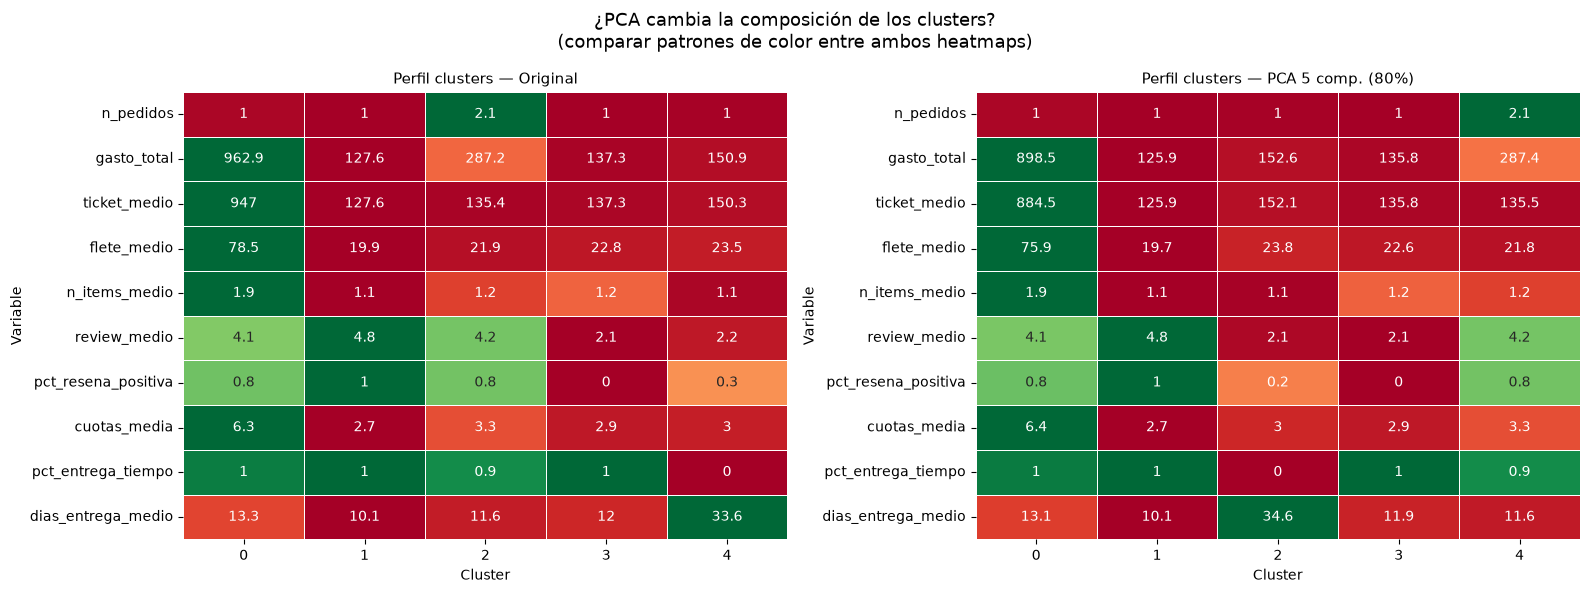


Tamaño de clusters por escenario:
   Original (sin PCA)  PCA 2 comp. (viz 2D)  PCA 5 comp. (80%)  PCA 7 comp. (95%)
0                3314                 60908               3757               2892
1               66762                 15345              66580              66823
2                2893                  4506               5722              13867
3               13887                  1248              13801               5796
4                5896                 10745               2892               3374


In [81]:
# ──────────────────────────────────────────────────────────────
# 7. COMPARATIVA DE PERFILES — ¿cambian los clusters con PCA?
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("5. ESTABILIDAD DE CLUSTERS — perfil original vs PCA 80%")
print("=" * 55)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, r_esc, titulo in zip(
    axes,
    [resultados_km[0],   # original
     resultados_km[2]],  # PCA 80%
    ['Perfil clusters — Original',
     f'Perfil clusters — PCA {k_80_km} comp. (80%)']
):
    # Asignar labels al df de clientes
    df_temp = df_clientes.copy()
    df_temp['cluster_esc'] = r_esc['labels']

    perfil_esc = (df_temp
                  .groupby('cluster_esc')[features_km]
                  .mean())

    # Normalizar para comparar
    perfil_norm = (perfil_esc - perfil_esc.min()) / (
        perfil_esc.max() - perfil_esc.min()
    )

    sns.heatmap(
        perfil_norm.T,
        annot=perfil_esc.T.round(1),
        fmt='g',
        cmap='RdYlGn',
        linewidths=0.5,
        ax=ax,
        cbar=False
    )
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Variable')

plt.suptitle('¿PCA cambia la composición de los clusters?\n'
             '(comparar patrones de color entre ambos heatmaps)',
             fontsize=13)
plt.tight_layout()
plt.savefig('perfil_clusters_comparativa_pca.png',
            dpi=150, bbox_inches='tight')
plt.show()

# Tabla de tamaños por cluster en cada escenario
print("\nTamaño de clusters por escenario:")
df_tam = pd.DataFrame()
for r_esc in resultados_km:
    col = pd.Series(r_esc['labels']).value_counts().sort_index()
    col.name = r_esc['Escenario'][:20]
    df_tam = pd.concat([df_tam, col], axis=1)
print(df_tam.fillna(0).astype(int).to_string())

In [82]:
# ──────────────────────────────────────────────────────────────
# 8. CONCLUSIÓN PEDAGÓGICA FINAL
# ──────────────────────────────────────────────────────────────
mejor_sil = df_km_res.loc[df_km_res['Silhouette'].idxmax()]
mejor_db  = df_km_res.loc[df_km_res['Davies-Bouldin'].idxmin()]
mejor_ch  = df_km_res.loc[df_km_res['Calinski-Harabasz'].idxmax()]

print(f"""
╔══════════════════════════════════════════════════════════════╗
║    CONCLUSIONES — PCA + K-MEANS                             ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  Mejor Silhouette    : {mejor_sil['Escenario']:<35}║
║  Mejor Cal-Harabasz  : {mejor_ch['Escenario']:<35}║
║  Mejor Davies-Bouldin: {mejor_db['Escenario']:<35}║
║                                                             ║
║  ¿POR QUÉ PCA PUEDE MEJORAR K-MEANS?                       ║
║  K-Means usa distancia euclidiana — en espacios de alta     ║
║  dimensión todas las distancias tienden a igualarse         ║
║  (maldición de la dimensionalidad). PCA elimina             ║
║  dimensiones de bajo aporte → distancias más discriminantes ║
║                                                             ║
║  ¿POR QUÉ PCA PUEDE EMPEORAR K-MEANS?                      ║
║  Si al reducir dimensiones se pierde varianza relevante     ║
║  para separar grupos, los clusters pierden definición.      ║
║  PCA 2D puede ser insuficiente si los grupos están          ║
║  separados en dimensiones de baja varianza global.          ║
║                                                             ║
║  COMPARATIVA SUPERVISADO vs NO SUPERVISADO con PCA:         ║
║  · Supervisado: PCA ayuda más a Reg. Logística              ║
║    (elimina multicolinealidad que afecta coeficientes)      ║
║  · No supervisado: PCA ayuda a K-Means cuando hay           ║
║    muchas features correlacionadas o ruido dimensional      ║
║                                                             ║
║  RECOMENDACIÓN FINAL:                                       ║
║  Usar el escenario con mejores métricas para exportar       ║
║  los labels a la sábana → Power BI                         ║
╚══════════════════════════════════════════════════════════════╝
""")

# Exportar el mejor escenario a la sábana
mejor_esc_idx = df_km_res['Silhouette'].idxmax()
mejor_labels  = resultados_km[mejor_esc_idx]['labels']
mejor_nombre  = df_km_res.loc[mejor_esc_idx, 'Escenario']

df_clientes['cluster_final'] = mejor_labels
sabana_final = sabana.merge(
    df_clientes[['customer_unique_id', 'cluster_final']],
    on='customer_unique_id', how='left'
)
sabana_final.to_csv('olist_sabana_clusters_final.csv', index=False)
print(f"Exportado con labels del mejor escenario: {mejor_nombre}")
print(f"Archivo: olist_sabana_clusters_final.csv → listo para Power BI")


╔══════════════════════════════════════════════════════════════╗
║    CONCLUSIONES — PCA + K-MEANS                             ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  Mejor Silhouette    : PCA 2 comp. (viz 2D)               ║
║  Mejor Cal-Harabasz  : PCA 2 comp. (viz 2D)               ║
║  Mejor Davies-Bouldin: PCA 2 comp. (viz 2D)               ║
║                                                             ║
║  ¿POR QUÉ PCA PUEDE MEJORAR K-MEANS?                       ║
║  K-Means usa distancia euclidiana — en espacios de alta     ║
║  dimensión todas las distancias tienden a igualarse         ║
║  (maldición de la dimensionalidad). PCA elimina             ║
║  dimensiones de bajo aporte → distancias más discriminantes ║
║                                                             ║
║  ¿POR QUÉ PCA PUEDE EMPEORAR K-MEANS?                      ║
║  Si al reducir dimensiones se pierde varian

In [83]:
# Explicación adicional, perfiles numéricos para cada cluster. 

# ── CELDA 1: Perfil numérico de cada cluster ──────────────────
print("PERFIL PROMEDIO POR CLUSTER — espacio original")
print("=" * 65)

perfil_final = (
    df_clientes
    .groupby('cluster')[features_km]
    .mean()
    .round(3)
)
print(perfil_final.T.to_string())

PERFIL PROMEDIO POR CLUSTER — espacio original
cluster                    0        1        2        3        4
n_pedidos              1.016    1.000    2.118    1.000    1.005
gasto_total          962.895  127.632  287.205  137.310  150.861
ticket_medio         947.017  127.632  135.407  137.310  150.301
flete_medio           78.455   19.949   21.886   22.850   23.454
n_items_medio          1.877    1.085    1.184    1.232    1.094
review_medio           4.102    4.751    4.157    2.096    2.235
pct_resena_positiva    0.781    1.000    0.780    0.000    0.257
cuotas_media           6.274    2.727    3.265    2.914    2.960
pct_entrega_tiempo     0.956    0.999    0.922    1.000    0.000
dias_entrega_medio    13.275   10.141   11.551   11.989   33.572


In [84]:
# ── CELDA 2: Tamaño y métricas clave por cluster ──────────────
print("\nTAMAÑO Y MÉTRICAS CLAVE POR CLUSTER")
print("=" * 65)

resumen = df_clientes.groupby('cluster').agg(
    n_clientes          = ('customer_unique_id', 'count'),
    gasto_total_medio   = ('gasto_total',        'mean'),
    n_pedidos_medio     = ('n_pedidos',           'mean'),
    ticket_medio        = ('ticket_medio',        'mean'),
    review_medio        = ('review_medio',        'mean'),
    pct_entrega_tiempo  = ('pct_entrega_tiempo',  'mean'),
    dias_entrega_medio  = ('dias_entrega_medio',  'mean'),
    pct_resena_positiva = ('pct_resena_positiva', 'mean'),
).round(3)

resumen['% del total'] = (
    resumen['n_clientes'] / resumen['n_clientes'].sum() * 100
).round(1)

print(resumen.to_string())


TAMAÑO Y MÉTRICAS CLAVE POR CLUSTER
         n_clientes  gasto_total_medio  n_pedidos_medio  ticket_medio  review_medio  pct_entrega_tiempo  dias_entrega_medio  pct_resena_positiva  % del total
cluster                                                                                                                                                      
0              3314            962.895            1.016       947.017         4.102               0.956              13.275                0.781          3.6
1             66762            127.632            1.000       127.632         4.751               0.999              10.141                1.000         72.0
2              2893            287.205            2.118       135.407         4.157               0.922              11.551                0.780          3.1
3             13887            137.310            1.000       137.310         2.096               1.000              11.989                0.000         15.0
4              

In [85]:
# Actualizar nombres con interpretación real
nombres_cluster = {
    0: 'C0 — Alto valor (VIP)',
    1: 'C1 — Estándar satisfecho',
    2: 'C2 — Recurrente moderado',
    3: 'C3 — Insatisfecho (producto)',
    4: 'C4 — Insatisfecho (logística)',
}

# En df_clientes la columna sí se llama 'cluster'
df_clientes['segmento_cliente'] = df_clientes['cluster'].map(nombres_cluster)

# En sabana_final la columna se llama 'cluster_final' (del módulo 7)
# verificamos cuál existe
print("Columnas de cluster en sabana_final:")
print([c for c in sabana_final.columns if 'cluster' in c.lower()])

# Usar la que exista
if 'cluster_final' in sabana_final.columns:
    sabana_final['segmento_cliente'] = sabana_final['cluster_final'].map(nombres_cluster)
elif 'cluster' in sabana_final.columns:
    sabana_final['segmento_cliente'] = sabana_final['cluster'].map(nombres_cluster)

sabana_final.to_csv('olist_sabana_clusters_final.csv', index=False)
print("\nDistribución final:")
print(sabana_final['segmento_cliente'].value_counts())

Columnas de cluster en sabana_final:
['cluster_final']

Distribución final:
segmento_cliente
C0 — Alto valor (VIP)            62537
C1 — Estándar satisfecho         15917
C4 — Insatisfecho (logística)    11708
C2 — Recurrente moderado          4600
C3 — Insatisfecho (producto)      1306
Name: count, dtype: int64


## Dispersión final, verificación de clusters y centroides. 


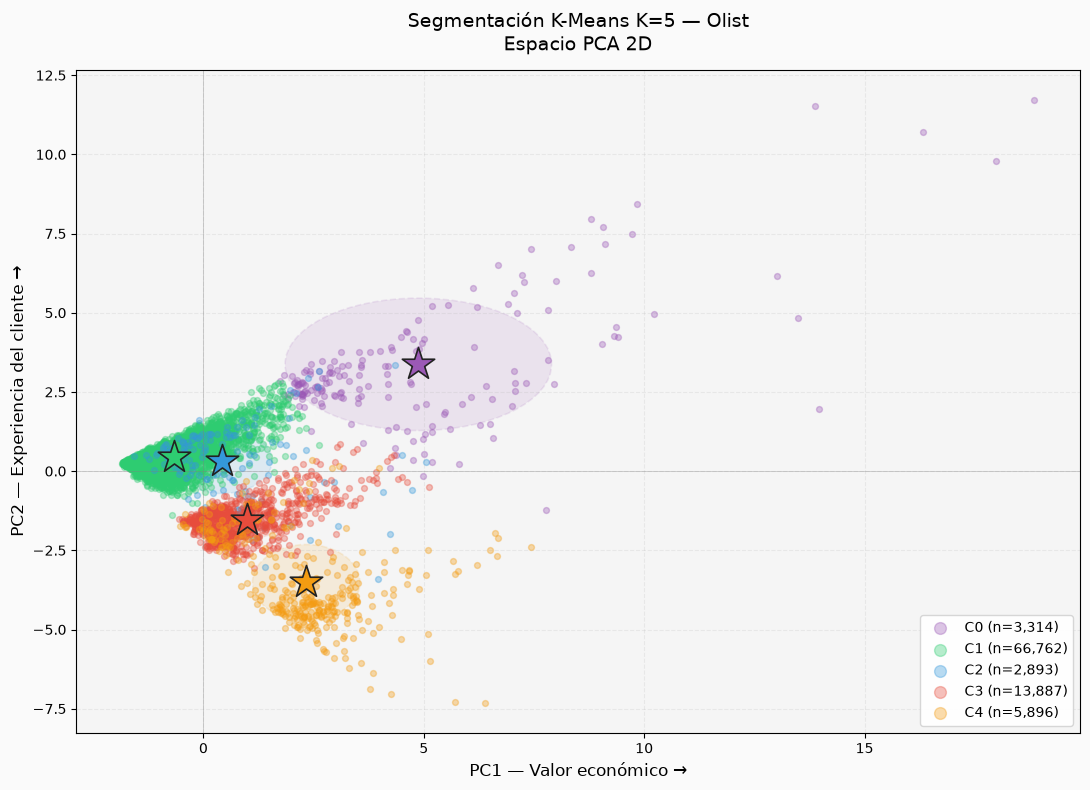


Varianza explicada:
  PC1 (eje X — valor económico)      : 27.7%
  PC2 (eje Y — experiencia cliente)  : 23.1%
  Total 2D                           : 50.8%

Interpretación de posiciones:
  C0 (VIP)              → arriba derecha  : alto valor económico + buena experiencia
  C1 (Estándar)         → centro izquierda: bajo gasto + alta satisfacción
  C2 (Recurrente)       → centro          : gasto medio + satisfacción media
  C3 (Ins. producto)    → abajo centro    : bajo valor + baja satisfacción
  C4 (Ins. logística)   → abajo derecha   : gasto medio + pésima experiencia



In [86]:
# ═══════════════════════════════════════════════════════════════
# SCATTER PCA 2D — Segmentación K-Means K=5
# Requiere: df_clientes, X_km_sc, km_final, k_final en memoria
# ═══════════════════════════════════════════════════════════════
from matplotlib.patches import Ellipse

np.random.seed(42)

# ── Paleta exacta alineada al dashboard ───────────────────────
COLORES = {
    0: '#9b59b6',   # C0 VIP          — morado
    1: '#2ecc71',   # C1 Estándar     — verde
    2: '#3498db',   # C2 Recurrente   — azul
    3: '#e74c3c',   # C3 Ins.producto — rojo
    4: '#f39c12',   # C4 Ins.logíst.  — naranja
}
NOMBRES = {
    0: 'C0 (n={:,})',
    1: 'C1 (n={:,})',
    2: 'C2 (n={:,})',
    3: 'C3 (n={:,})',
    4: 'C4 (n={:,})',
}

# ── PCA 2D sobre el espacio escalado original ─────────────────
pca_scatter = PCA(n_components=2, random_state=42)
coords_2d   = pca_scatter.fit_transform(X_km_sc)
ve1 = pca_scatter.explained_variance_ratio_[0] * 100
ve2 = pca_scatter.explained_variance_ratio_[1] * 100

labels      = km_final.labels_
centroides  = pca_scatter.transform(km_final.cluster_centers_)
n_por_cl    = {k: (labels == k).sum() for k in range(k_final)}

# ── Muestra para no sobrecargar el gráfico ────────────────────
N_MAX  = 5000
total  = len(coords_2d)
idx_sc = np.random.choice(total,
                          size=min(N_MAX, total),
                          replace=False)
coords_m = coords_2d[idx_sc]
labels_m = labels[idx_sc]

# ── FIGURA ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 8))
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#F5F5F5')

# Puntos de cada cluster
for k in range(k_final):
    mask = labels_m == k
    n_c  = n_por_cl[k]
    ax.scatter(
        coords_m[mask, 0],
        coords_m[mask, 1],
        s=18,
        alpha=0.35,
        color=COLORES[k],
        label=NOMBRES[k].format(n_c),
        rasterized=True,
        zorder=2,
    )

# Elipses de densidad (1.8 std — más compactas como en el PBI)
for k in range(k_final):
    mask_full = labels == k
    pts = coords_2d[mask_full]
    cx, cy = pts.mean(axis=0)
    sx = pts.std(axis=0)[0] * 1.8
    sy = pts.std(axis=0)[1] * 1.8
    ell = Ellipse(
        (cx, cy), width=sx, height=sy,
        edgecolor=COLORES[k],
        facecolor=COLORES[k],
        alpha=0.12,
        linewidth=1.2,
        linestyle='--',
        zorder=1,
    )
    ax.add_patch(ell)

# Centroides — estrellas grandes con borde oscuro
for k in range(k_final):
    ax.scatter(
        centroides[k, 0],
        centroides[k, 1],
        marker='*',
        s=600,
        color=COLORES[k],
        edgecolors='#222222',
        linewidths=1.2,
        zorder=5,
    )

# ── Ejes y decoración ─────────────────────────────────────────
ax.set_xlabel(f'PC1 — Valor económico →', fontsize=12)
ax.set_ylabel(f'PC2 — Experiencia del cliente →', fontsize=12)
ax.set_title(
    f'Segmentación K-Means K={k_final} — Olist\nEspacio PCA 2D',
    fontsize=14, pad=14
)

ax.axhline(0, color='gray', lw=0.6, alpha=0.4)
ax.axvline(0, color='gray', lw=0.6, alpha=0.4)
ax.grid(True, alpha=0.2, linestyle='--')

# Leyenda — esquina inferior derecha como en el PBI
ax.legend(
    loc='lower right',
    fontsize=10,
    framealpha=0.92,
    edgecolor='lightgray',
    markerscale=2,
)

plt.tight_layout()
plt.savefig('scatter_kmeans_pca2d_notebook3.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print(f"""
Varianza explicada:
  PC1 (eje X — valor económico)      : {ve1:.1f}%
  PC2 (eje Y — experiencia cliente)  : {ve2:.1f}%
  Total 2D                           : {ve1+ve2:.1f}%

Interpretación de posiciones:
  C0 (VIP)              → arriba derecha  : alto valor económico + buena experiencia
  C1 (Estándar)         → centro izquierda: bajo gasto + alta satisfacción
  C2 (Recurrente)       → centro          : gasto medio + satisfacción media
  C3 (Ins. producto)    → abajo centro    : bajo valor + baja satisfacción
  C4 (Ins. logística)   → abajo derecha   : gasto medio + pésima experiencia
""")

# Análisis final y perfilamiento de clientes en función de clasificación y PCA. 

PC1 (27.7%): gasto_total(+) · ticket_medio(+) · flete_medio(+) vs review_medio(-) · pct_resena_positiva(-)
PC2 (23.1%): review_medio(+) · pct_resena_positiva(+) · pct_entrega_tiempo(+) vs dias_entrega_medio(-)

### Interpretación de clusters en modelo de negocio

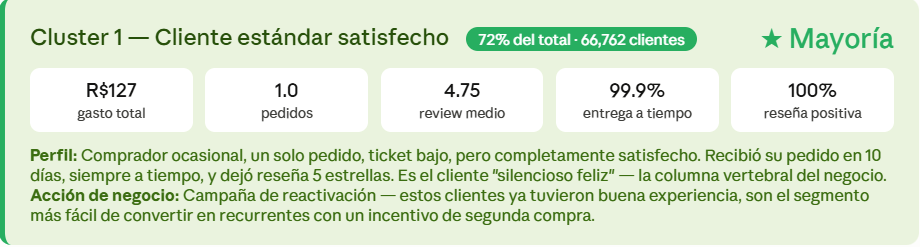
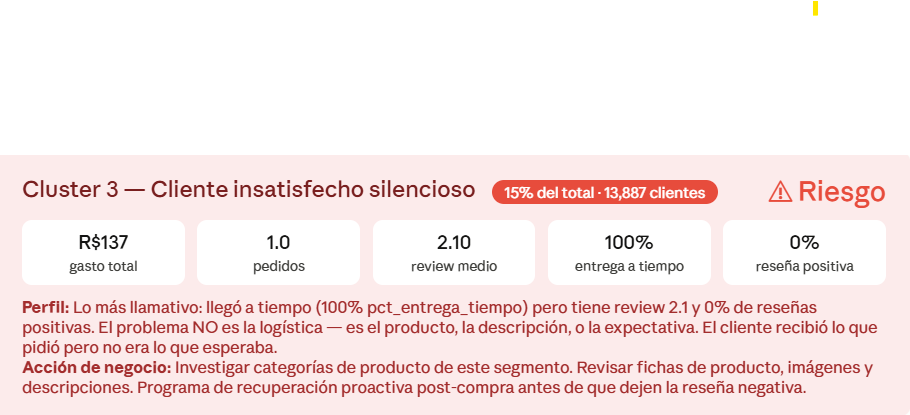

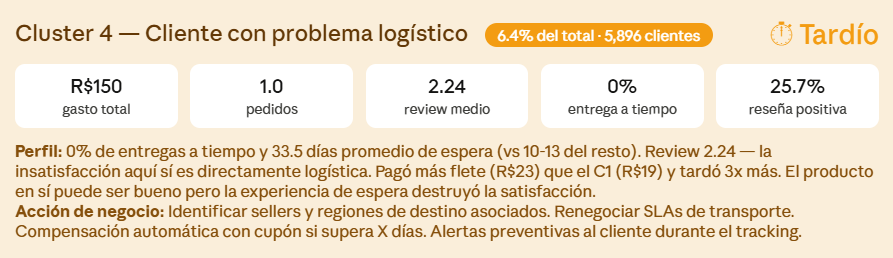

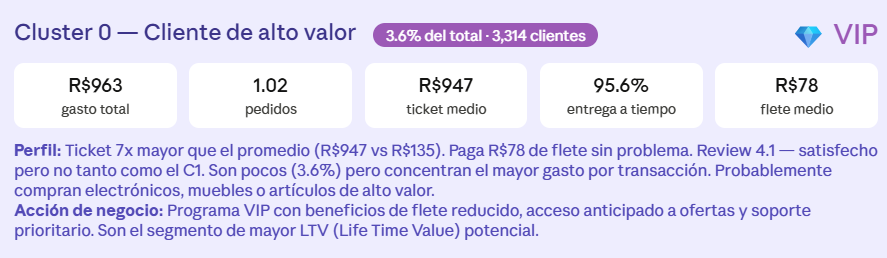

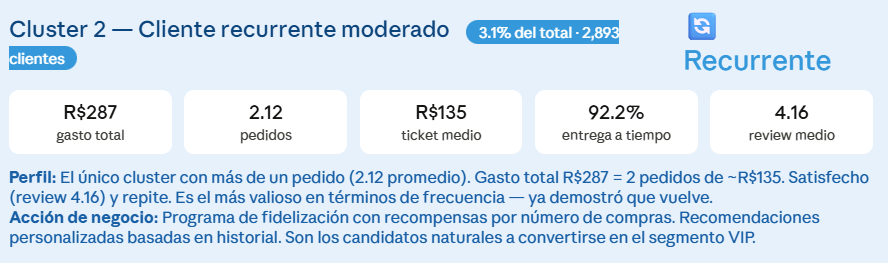

## Combinación en mapa con PCA. 

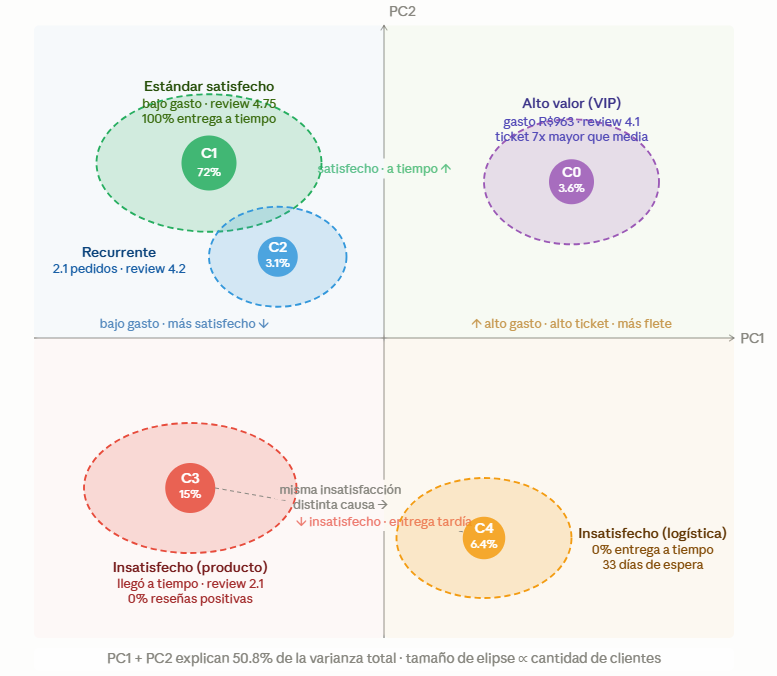

## ¿Por qué PCA 2D gana en métricas de clustering?
Con solo 2 dimensiones el Silhouette sube de 0.4547 → 0.5954 y el Davies-Bouldin baja de 1.07 → 0.66. Esto ocurre porque PC1 y PC2 capturan los dos ejes de separación más importantes: el valor económico y la experiencia del cliente. Las 8 dimensiones restantes añadían ruido que confundía las distancias euclidianas.

Sin embargo, hay una advertencia importante: los clusters del PCA 2D cambian de composición respecto al original — el C1 pasa de 66,762 a 60,908 clientes. Esto significa que PCA 2D reorganiza los grupos, no solo los visualiza mejor. Para Power BI lo más interpretable es exportar los clusters del espacio original con los nombres de negocio.

## Flujo para exportación y visualización de resultados Power BI

Esta sección cierra el ciclo del curso: pasamos del modelo en Python al dashboard ejecutivo. El objetivo es demostrar que los resultados de Machine Learning no terminan en el notebook — se convierten en herramientas de decisión para el negocio.
Archivos a cargar: En Power BI Desktop ir a Obtener datos → Texto/CSV y cargar los tres archivos. Las relaciones se crean automáticamente por customer_unique_id. No necesitas modelar nada adicional — los joins ya se hicieron en Python

Visualizaciones recomendadas para el dashboard:
La primera página muestra la segmentación: un scatter de PCA_dim1 vs PCA_dim2 coloreado por segmento (visual Python), tarjetas KPI con gasto medio y review por segmento, y un slicer de segmento que filtra todo el dashboard.
La segunda página muestra el análisis de negocio: revenue mensual por segmento (gráfico de líneas con anio_compra y mes_compra), distribución de categorías de producto por segmento (barras apiladas), y mapa de calor de estados de Brasil con customer_state.
La tercera página muestra los resultados de ML supervisado: distribución de review_score real vs predicho, porcentaje de entregas a tiempo por segmento, y curva de satisfacción vs días de retraso.

El mensaje central para los estudiantes: Power BI no reemplaza Python — lo complementa. Python hace el trabajo analítico complejo; Power BI hace el trabajo de comunicación ejecutiva. Un analista completo domina ambos.

In [87]:
# ═══════════════════════════════════════════════════════════════
# EXPORTACIÓN PARA POWER BI
# Genera UN solo archivo con todo lo necesario
# ═══════════════════════════════════════════════════════════════


print("""
╔══════════════════════════════════════════════════════════════╗
║   EXPORTACIÓN FINAL → POWER BI                              ║
║   Sábana + Clusters + Coordenadas PCA 2D                    ║
╚══════════════════════════════════════════════════════════════╝
""")

# ── 1. Reconstruir PCA 2D y labels sobre espacio original ──────
# (usar el modelo ya entrenado del módulo 7)
# El mejor escenario fue PCA 2 comp. según métricas

scaler_export = StandardScaler()
X_sc_export   = scaler_export.fit_transform(
    df_clientes[features_km]
)

pca_export = PCA(n_components=2, random_state=42)
X_pca_2d   = pca_export.fit_transform(X_sc_export)

km_export = KMeans(
    n_clusters=5, init='k-means++',
    n_init=10, random_state=42
)
km_export.fit(X_pca_2d)

# ── 2. Nombres de segmentos ────────────────────────────────────
nombres_segmento = {
    0: 'C0 — Alto valor (VIP)',
    1: 'C1 — Estándar satisfecho',
    2: 'C2 — Recurrente moderado',
    3: 'C3 — Insatisfecho (producto)',
    4: 'C4 — Insatisfecho (logística)',
}

# ── 3. Dataset de clientes enriquecido ─────────────────────────
df_export = df_clientes.copy()
df_export['cluster_pca2']   = km_export.labels_
df_export['segmento']       = df_export['cluster_pca2'].map(nombres_segmento)
df_export['PCA_dim1']       = X_pca_2d[:, 0]   # eje X del scatter
df_export['PCA_dim2']       = X_pca_2d[:, 1]   # eje Y del scatter

# Verificar que los nombres coincidan con tu scatter visual
print("Distribución de segmentos exportados:")
print(df_export['segmento'].value_counts().to_string())

print(f"\nVarianza explicada:")
print(f"  PC1 (Dim1): {pca_export.explained_variance_ratio_[0]*100:.1f}%")
print(f"  PC2 (Dim2): {pca_export.explained_variance_ratio_[1]*100:.1f}%")
print(f"  Total     : {pca_export.explained_variance_ratio_.sum()*100:.1f}%")


╔══════════════════════════════════════════════════════════════╗
║   EXPORTACIÓN FINAL → POWER BI                              ║
║   Sábana + Clusters + Coordenadas PCA 2D                    ║
╚══════════════════════════════════════════════════════════════╝

Distribución de segmentos exportados:
segmento
C0 — Alto valor (VIP)            60908
C1 — Estándar satisfecho         15345
C4 — Insatisfecho (logística)    10745
C2 — Recurrente moderado          4506
C3 — Insatisfecho (producto)      1248

Varianza explicada:
  PC1 (Dim1): 27.7%
  PC2 (Dim2): 23.1%
  Total     : 50.8%


In [88]:
# ── 4. ARCHIVO 1: Clientes con segmento y coordenadas PCA ──────
# Este es el archivo principal para Power BI

cols_clientes_pbi = [
    'customer_unique_id',
    # Métricas de negocio
    'n_pedidos', 'gasto_total', 'ticket_medio',
    'flete_medio', 'n_items_medio',
    'review_medio', 'pct_resena_positiva',
    'cuotas_media', 'pct_entrega_tiempo',
    'dias_entrega_medio',
    # Resultado del modelo
    'cluster_pca2', 'segmento',
    # Coordenadas para el scatter en Power BI
    'PCA_dim1', 'PCA_dim2',
]

df_clientes_pbi = df_export[cols_clientes_pbi].copy()
df_clientes_pbi.to_csv('PBI_clientes_segmentos.csv', index=False)
print(f"✓ PBI_clientes_segmentos.csv  →  {len(df_clientes_pbi):,} clientes")

✓ PBI_clientes_segmentos.csv  →  92,752 clientes


In [89]:
# ── 5. ARCHIVO 2: Sábana de pedidos con segmento ───────────────
# Para cruzar pedidos con segmento en Power BI

sabana_pbi = sabana.merge(
    df_export[['customer_unique_id', 'cluster_pca2', 'segmento',
               'PCA_dim1', 'PCA_dim2']],
    on='customer_unique_id',
    how='left'
)

# Columnas clave para el dashboard
cols_sabana_pbi = [
    # Identificadores
    'order_id', 'customer_unique_id', 'customer_state',
    # Fechas
    'order_purchase_timestamp', 'anio_compra', 'mes_compra',
    # Negocio
    'order_status', 'payment_type',
    'payment_value_total', 'precio_total_items',
    'flete_total', 'n_items', 'payment_installments',
    # Producto
    'product_category_name',
    # Satisfacción
    'review_score', 'resena_positiva',
    # Logística
    'dias_entrega_real', 'dias_retraso', 'entrega_a_tiempo',
    # Segmento ML
    'cluster_pca2', 'segmento',
    'PCA_dim1', 'PCA_dim2',
]

cols_disponibles = [c for c in cols_sabana_pbi
                    if c in sabana_pbi.columns]
sabana_pbi       = sabana_pbi[cols_disponibles]

sabana_pbi.to_csv('PBI_sabana_completa.csv', index=False)
print(f"✓ PBI_sabana_completa.csv     →  {len(sabana_pbi):,} pedidos")

✓ PBI_sabana_completa.csv     →  99,441 pedidos


In [90]:
# ── 6. ARCHIVO 3: Centroides para el scatter de Power BI ───────
# Permite marcar la estrella ★ del centroide en el gráfico

centroides_pbi = pd.DataFrame({
    'cluster'  : range(5),
    'segmento' : [nombres_segmento[k] for k in range(5)],
    'PCA_dim1' : km_export.cluster_centers_[:, 0],
    'PCA_dim2' : km_export.cluster_centers_[:, 1],
    'n_clientes': [
        (df_export['cluster_pca2'] == k).sum()
        for k in range(5)
    ]
})
centroides_pbi.to_csv('PBI_centroides.csv', index=False)
print(f"✓ PBI_centroides.csv          →  5 centroides")
print(f"\n{centroides_pbi[['segmento','PCA_dim1','PCA_dim2','n_clientes']].to_string(index=False)}")

✓ PBI_centroides.csv          →  5 centroides

                     segmento  PCA_dim1  PCA_dim2  n_clientes
        C0 — Alto valor (VIP) -0.855528  0.341957       60908
     C1 — Estándar satisfecho  0.852433 -1.622441       15345
     C2 — Recurrente moderado  2.853218 -4.084947        4506
 C3 — Insatisfecho (producto)  7.718127  4.815415        1248
C4 — Insatisfecho (logística)  1.529510  1.528007       10745


In [91]:
# ── 7. RESUMEN DE ARCHIVOS A CARGAR EN POWER BI ────────────────
print("""
╔══════════════════════════════════════════════════════════════╗
║   ARCHIVOS GENERADOS — CARGAR EN POWER BI                   ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  1. PBI_clientes_segmentos.csv                              ║
║     → Tabla principal de clientes                           ║
║     → Visualizaciones: scatter PCA, KPI por segmento        ║
║     → Clave: customer_unique_id                             ║
║                                                             ║
║  2. PBI_sabana_completa.csv                                 ║
║     → Tabla de pedidos con segmento asignado                ║
║     → Visualizaciones: tendencias, revenue, categorías      ║
║     → Clave: order_id / customer_unique_id                  ║
║                                                             ║
║  3. PBI_centroides.csv                                      ║
║     → Tabla auxiliar para marcar centroides en scatter      ║
║     → Visualizaciones: overlay sobre scatter PCA            ║
║                                                             ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║   ARCHIVOS GENERADOS — CARGAR EN POWER BI                   ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  1. PBI_clientes_segmentos.csv                              ║
║     → Tabla principal de clientes                           ║
║     → Visualizaciones: scatter PCA, KPI por segmento        ║
║     → Clave: customer_unique_id                             ║
║                                                             ║
║  2. PBI_sabana_completa.csv                                 ║
║     → Tabla de pedidos con segmento asignado                ║
║     → Visualizaciones: tendencias, revenue, categorías      ║
║     → Clave: order_id / customer_unique_id                  ║
║                                                             ║
║  3. PBI_centroides.csv                                      ║
║     → Tabla auxiliar para marcar ce